# CSR-MMDiff: Clear-Sky-Residual Multimodal Diffusion for 15-min Probabilistic PV Forecasting (SKIPP'D)

Joint sky-image + PV diffusion (PV-MM-Diffusion family) with DDIM sampling. Changes relative to the previous version of this notebook:

**Method (novel components)**
1. **Clear-sky residual diffusion.** The PV branch diffuses the residual w.r.t. clear-sky smart persistence, $x_0 = (P_{t+h} - \hat P^{\mathrm{SPM}}_{t+h}) / s$, and the image branch diffuses the change w.r.t. the last observed frame. The network only models the deviation from a physical prior.
2. **Physics-informed conditioning.** Clear-sky power $P_{\mathrm{clr}}$ for the 16 history *and future* frames (known in advance), the persistence anchor and explicit modality-availability flags (fixes the ambiguous zero placeholder, which meant 15 kW in the old $[-1,1]$ scaling).
3. **Cloud-aware RS-PV-MMA.** Learned spatial attention pooling (instead of global average pooling) before the PV↔image cross-attention, plus one extra fusion in the decoder.
4. **Physics-constrained DDIM.** Every predicted $x_0$ is projected onto $0 \le P \le P_{\max}$ (and valid pixel range).
5. **Sky-image guidance.** The empty-frame placeholder training yields an image-free model for free; $v = v_{SI+PV} + g\,(v_{SI+PV} - v_{PV})$ is tuned on validation.
6. **Lead-time-aware spread calibration** fitted on validation windows only.

**Training:** v-prediction, cosine schedule, Min-SNR-γ weighting, EMA, fp16 mixed precision, both GPUs (MirroredStrategy), wall-clock budget with auto-resume.

**Evaluation:** full SKIPP'D test set (same protocol as before) **and** a paper-matched cloudy subset (5 most variable test days, clear-sky windows removed), with SPM, probabilistic persistence (PeEn), two-stage and previous-version baselines. All tuning uses validation days only.

Run headless (recommended for the 20 h run):
```bash
jupyter nbconvert --to script ddim_improved.ipynb        # -> ddim_improved.py
tmux new -s train 'python ddim_improved.py 2>&1 | tee run.log'
tail -f checkpoints/pvmm_csr_v2/train_log.txt
```
Re-running resumes from the last checkpoint and continues until `train_hours` of training time have been used.

## Cell 1: Environment, multi-GPU strategy & mixed precision

In [8]:
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
# SMOKE_TEST=1 -> tiny CPU-only run (2 logical CPU replicas) on synthetic data, to check the full code path
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

import math
import time
import json
import glob
import random
import datetime
import gc
from dataclasses import dataclass, field
from typing import List, Tuple, Dict, Any, Optional

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # headless run (python script / nbconvert): never block on plt.show()
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set seeds for deterministic reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

if SMOKE_TEST:
    tf.config.set_visible_devices([], "GPU")
    _cpu = tf.config.list_physical_devices("CPU")[0]
    tf.config.set_logical_device_configuration(
        _cpu, [tf.config.LogicalDeviceConfiguration()] * 2
    )

# Configure GPU memory growth to prevent out-of-memory errors
physical_gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow version: {tf.__version__} | Keras version: {keras.__version__}")
print(f"Available GPUs: {len(physical_gpus)}")
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print(f"  Configured memory growth for: {gpu.name}")
    except RuntimeError as e:
        print(f"  Could not configure {gpu.name}: {e}")

# ---- Use every GPU: synchronous data-parallel training, one model replica per GPU.
# ALLREDUCE=nccl|hierarchical|one_device. Hierarchical copy is the default because NCCL peer-to-peer
# can hang on consumer GeForce boards without P2P support.
_allreduce = os.environ.get("ALLREDUCE", "hierarchical")
if SMOKE_TEST:
    strategy = tf.distribute.MirroredStrategy(
        ["/cpu:0", "/cpu:1"], cross_device_ops=tf.distribute.ReductionToOneDevice()
    )
elif len(physical_gpus) > 1:
    _cross = {
        "nccl": tf.distribute.NcclAllReduce(),
        "hierarchical": tf.distribute.HierarchicalCopyAllReduce(),
        "one_device": tf.distribute.ReductionToOneDevice(),
    }[_allreduce]
    strategy = tf.distribute.MirroredStrategy(cross_device_ops=_cross)
else:
    strategy = tf.distribute.get_strategy()
N_REPLICAS = strategy.num_replicas_in_sync

# ---- Mixed precision: fp16 tensor cores on Ampere (about 2x throughput, half the activation memory).
# Loss scaling is done manually in the train step so the finite-gradient check is global across GPUs.
USE_MIXED_PRECISION = (bool(physical_gpus) and not SMOKE_TEST) or os.environ.get(
    "FORCE_MIXED_PRECISION"
) == "1"
keras.mixed_precision.set_global_policy(
    "mixed_float16" if USE_MIXED_PRECISION else "float32"
)
print(
    f"Replicas in sync: {N_REPLICAS} | precision policy: "
    f"{keras.mixed_precision.global_policy().name} | smoke test: {SMOKE_TEST}"
)

# Plotting style setup
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120
print("Environment initialized successfully.")

TensorFlow version: 2.21.0 | Keras version: 3.15.1
Available GPUs: 2
  Configured memory growth for: /physical_device:GPU:0
  Configured memory growth for: /physical_device:GPU:1
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Replicas in sync: 2 | precision policy: mixed_float16 | smoke test: False
Environment initialized successfully.


## Cell 2: Hyperparameters & configuration

In [9]:
@dataclass
class HorizonConfig:
    horizon_name: str = "15min"  # 15-minute forecast horizon
    lead_time_minutes: int = 15
    hist_frames: int = 8  # 8 frames * 2 min = 16 minutes history
    fut_frames: int = 8  # 8 future frames * 2 min = 16 minutes (~15 min horizon)
    cadence_minutes: int = 2  # 2-minute sampling of the 1-minute native records
    window_sizes: List[int] = field(default_factory=lambda: [1, 4, 8])  # RS-PV-MMA windows
    rs_max_shift: int = 1  # random temporal shift of the image stream in RS-PV-MMA (training only)

    # ---- network / optimisation
    base_dim: int = 32  # channel widths [32, 64, 128, 256]
    per_replica_batch: int = 16  # global batch = per_replica_batch * number of GPUs
    learning_rate: float = 2e-4
    min_lr_frac: float = 0.05  # cosine decay (over the wall-clock budget) down to 5% of the peak LR
    warmup_steps: int = 1000
    grad_clip: float = 1.0
    ema_decay: float = 0.9995

    # ---- diffusion
    diffusion_T: int = 1000
    noise_schedule: str = "cosine"
    min_snr_gamma: float = 5.0  # Min-SNR-gamma loss weighting
    lambda_pv: float = 1.0
    lambda_img: float = 0.5
    mode_weights: Tuple[float, float, float] = (0.7, 0.15, 0.15)  # SI+PV / SI-only / PV-only

    # ---- training budget, validation, early stopping
    train_hours: float = 20.0  # wall-clock budget, persisted across resumes
    max_steps: int = 10_000_000
    val_every: int = 2500  # steps between validation-CRPS checks
    val_windows: int = 512
    val_members: int = 8
    val_ddim_steps: int = 10
    patience: int = 12  # validation checks without improvement before stopping
    log_every: int = 100

    # ---- sampling / evaluation
    ddim_steps: int = 20
    eval_members: int = 30  # same ensemble size as PV-MM-Diffusion's main table
    sample_rows_per_replica: int = 64  # trajectories denoised in parallel per GPU (auto-halved on OOM)

    checkpoint_dir: str = "checkpoints/pvmm_csr_v2"
    batch_size: int = 8  # legacy two-stage baseline pipeline only

    @property
    def global_batch(self) -> int:
        return self.per_replica_batch * N_REPLICAS


CONFIG_15M = HorizonConfig()
if SMOKE_TEST:
    CONFIG_15M = HorizonConfig(
        base_dim=8,
        per_replica_batch=2,
        warmup_steps=5,
        train_hours=0.05,
        max_steps=24,
        val_every=12,
        val_windows=8,
        val_members=2,
        val_ddim_steps=2,
        log_every=6,
        ddim_steps=3,
        eval_members=4,
        sample_rows_per_replica=8,
        checkpoint_dir="checkpoints_smoke/pvmm_csr_v2",
    )

CONFIG = CONFIG_15M
ALL_CONFIGS = {"15min": CONFIG_15M}

# Global physical constants
PV_RATED_CAPACITY_KW = 30.0  # 30 kW Stanford rooftop array
IMAGE_RESOLUTION = (64, 64, 3)  # 64x64 RGB sky images
DIFFUSION_STEPS_T = CONFIG.diffusion_T
SIGMA_DATA = 0.5  # target std of the diffusion targets after scaling
MODEL_NAME = "CSR-MMDiff"  # clear-sky-residual multimodal diffusion (ours)

print("15-Minute Horizon configuration:")
print(
    f"  hist={CONFIG.hist_frames} / fut={CONFIG.fut_frames} frames at {CONFIG.cadence_minutes} min, "
    f"base_dim={CONFIG.base_dim}, global batch={CONFIG.global_batch} ({N_REPLICAS} x {CONFIG.per_replica_batch}), "
    f"budget={CONFIG.train_hours} h, DDIM steps={CONFIG.ddim_steps}, members={CONFIG.eval_members}"
)

15-Minute Horizon configuration:
  hist=8 / fut=8 frames at 2 min, base_dim=32, global batch=32 (2 x 16), budget=20.0 h, DDIM steps=20, members=30


## Cell 3: Data pipeline — real SKIPP'D dataset only

In [10]:
REQUIRED_FILES = [
    "trainval_images_log.npy",
    "trainval_pv_log.npy",
    "times_trainval.npy",
    "test_images_log.npy",
    "test_pv_log.npy",
    "times_test.npy",
]
# Load images fully into RAM (~4.3 GB for trainval) so random batch reads are fast; falls back to memmap.
LOAD_IMAGES_TO_RAM = True


def locate_skippd_data_dir() -> Optional[str]:
    """Searches for the extracted SKIPP'D dataset. Set env var SKIPPD_DATA_DIR to override."""
    candidates = []
    if os.environ.get("SKIPPD_DATA_DIR"):
        candidates.append(os.environ["SKIPPD_DATA_DIR"])
    candidates += [
        "/home/luqman-khan-57/content/data/extracted",
        "/home/haseebumer/content/data/extracted",
        "/content/data/extracted",
        "./data/extracted",
        "../data/extracted",
        os.path.expanduser("~/content/data/extracted"),
    ]
    for path in candidates:
        if not os.path.isdir(path):
            continue
        missing = [
            f for f in REQUIRED_FILES if not os.path.exists(os.path.join(path, f))
        ]
        if missing:
            print(f"Skipping {path}: missing {missing}")
            continue
        print(f"Found valid SKIPP'D dataset at: {path}")
        return path
    return None


DATA_DIR = locate_skippd_data_dir()
if DATA_DIR is None:
    raise FileNotFoundError(
        "Real SKIPP'D data not found. Extract the dataset so that these files exist in one folder:\n  "
        + "\n  ".join(REQUIRED_FILES)
        + "\nthen either place it in one of the candidate paths above or set the environment variable "
        "SKIPPD_DATA_DIR to that folder. (No synthetic fallback is used on purpose.)"
    )


def load_images(path):
    if LOAD_IMAGES_TO_RAM:
        try:
            return np.load(path)
        except MemoryError:
            print(f"Not enough RAM for {os.path.basename(path)}; using memory mapping instead.")
    return np.load(path, mmap_mode="r")


trainval_images_mmap = load_images(os.path.join(DATA_DIR, "trainval_images_log.npy"))
trainval_pv_raw = np.load(os.path.join(DATA_DIR, "trainval_pv_log.npy")).astype(
    np.float32
)
times_trainval_raw = np.load(
    os.path.join(DATA_DIR, "times_trainval.npy"), allow_pickle=True
)

test_images_mmap = load_images(os.path.join(DATA_DIR, "test_images_log.npy"))
test_pv_raw = np.load(os.path.join(DATA_DIR, "test_pv_log.npy")).astype(np.float32)
times_test_raw = np.load(os.path.join(DATA_DIR, "times_test.npy"), allow_pickle=True)

# ---- Sanity checks on the real data
for name, imgs, pv, ts in [
    ("trainval", trainval_images_mmap, trainval_pv_raw, times_trainval_raw),
    ("test", test_images_mmap, test_pv_raw, times_test_raw),
]:
    assert (
        len(imgs) == len(pv) == len(ts)
    ), f"{name}: length mismatch {len(imgs)}/{len(pv)}/{len(ts)}"
    assert imgs.dtype == np.uint8 and imgs.shape[1:] == IMAGE_RESOLUTION, (
        f"{name}: expected uint8 images of shape {IMAGE_RESOLUTION}, got {imgs.dtype} {imgs.shape[1:]}"
    )
    if not np.isfinite(pv).all():
        raise ValueError(
            f"{name}: PV array contains {np.sum(~np.isfinite(pv))} non-finite values"
        )
    t0, t1 = pd.to_datetime(ts[0]), pd.to_datetime(ts[-1])
    print(
        f"{name:9s}: {len(pv):>7d} records | images {imgs.shape[1:]} {imgs.dtype} "
        f"({'memmap' if isinstance(imgs, np.memmap) else 'RAM'}) | "
        f"PV kW min/mean/max = {pv.min():.2f}/{pv.mean():.2f}/{pv.max():.2f} | {t0} -> {t1}"
    )
    if pv.max() > PV_RATED_CAPACITY_KW * 1.05 or pv.min() < -0.5:
        print(
            f"  WARNING: {name} PV values fall outside [0, {PV_RATED_CAPACITY_KW}] kW; check units/normalization."
        )

Found valid SKIPP'D dataset at: /home/haseebumer/content/data/extracted


trainval :  349372 records | images (64, 64, 3) uint8 (RAM) | PV kW min/mean/max = 0.00/13.28/29.59 | 2017-03-09 06:47:00 -> 2019-10-26 17:59:20
test     :   14003 records | images (64, 64, 3) uint8 (RAM) | PV kW min/mean/max = 0.00/12.59/29.57 | 2017-09-15 07:11:00 -> 2019-10-19 18:15:30


## Cell 4: Clear-sky model, day-aware windowing, smart-persistence anchor & normalisation statistics

In [11]:
SITE_LAT, SITE_LON, SITE_ALT_M = 37.4275, -122.1697, 30.0  # Stanford rooftop
CS_MIN_KW = 1.0  # below this clear-sky power the clear-sky index is unstable -> plain persistence
K_MAX = 2.5  # clip on the clear-sky index (as in the original smart persistence baseline)


def normalize_pv(pv_kw):
    """Legacy [-1, 1] PV normalisation (used by the two-stage baseline only)."""
    return (pv_kw / (PV_RATED_CAPACITY_KW / 2.0)) - 1.0


def denormalize_pv(pv_norm):
    return (pv_norm + 1.0) * (PV_RATED_CAPACITY_KW / 2.0)


def normalize_images(imgs):
    """Normalizes uint8 images [0, 255] to float32 [-1.0, 1.0]."""
    if isinstance(imgs, np.ndarray):
        return (imgs.astype(np.float32) / 127.5) - 1.0
    return (tf.cast(imgs, tf.float32) / 127.5) - 1.0


def denormalize_images(imgs_norm):
    """Denormalizes images from [-1.0, 1.0] to uint8 [0, 255]."""
    if isinstance(imgs_norm, np.ndarray):
        return np.clip((imgs_norm + 1.0) * 127.5, 0.0, 255.0).astype(np.uint8)
    return tf.cast(tf.clip_by_value((imgs_norm + 1.0) * 127.5, 0.0, 255.0), tf.uint8)


# =====================================================================
# Clear-sky model (physics prior)
# =====================================================================
def _localize(times, tz):
    idx = pd.DatetimeIndex(pd.to_datetime(times))
    if idx.tz is None:
        return idx.tz_localize(tz, ambiguous="NaT", nonexistent="NaT")
    return idx.tz_convert(tz)


def clear_sky_ghi(times, tz: str):
    """Clear-sky GHI (W/m^2): pvlib Ineichen when available, else the Haurwitz model with the
    equation of time and longitude correction. Timestamps are interpreted in time zone `tz`."""
    loc_idx = _localize(times, tz)
    valid = ~np.asarray(loc_idx.isna())
    ghi = np.zeros(len(loc_idx), dtype=np.float64)
    try:
        import pvlib

        site = pvlib.location.Location(SITE_LAT, SITE_LON, altitude=SITE_ALT_M)
        ghi[valid] = site.get_clearsky(loc_idx[valid], model="ineichen")["ghi"].to_numpy()
        return np.nan_to_num(ghi), "pvlib Ineichen"
    except Exception as e:
        if not isinstance(e, ImportError):
            print(f"[clear-sky] pvlib failed ({type(e).__name__}: {e}); using the Haurwitz model.")
    utc = loc_idx[valid].tz_convert("UTC")
    doy = np.asarray(utc.dayofyear, dtype=np.float64)
    hour = (
        np.asarray(utc.hour, dtype=np.float64)
        + np.asarray(utc.minute, dtype=np.float64) / 60.0
        + np.asarray(utc.second, dtype=np.float64) / 3600.0
    )
    b = 2.0 * np.pi * (doy - 81.0) / 364.0
    eot_min = 9.87 * np.sin(2 * b) - 7.53 * np.cos(b) - 1.5 * np.sin(b)
    solar_time = hour + SITE_LON / 15.0 + eot_min / 60.0
    ha = np.radians(15.0 * (solar_time - 12.0))
    decl = np.radians(23.45 * np.sin(np.radians(360.0 / 365.0 * (doy - 81.0))))
    lat = np.radians(SITE_LAT)
    cosz = np.sin(lat) * np.sin(decl) + np.cos(lat) * np.cos(decl) * np.cos(ha)
    ghi[valid] = np.where(
        cosz > 0.01, 1098.0 * cosz * np.exp(-0.057 / np.maximum(cosz, 0.01)), 0.0
    )
    return np.nan_to_num(ghi), "Haurwitz"


def choose_clear_sky_timezone(times, pv, n: int = 40000):
    """The SKIPP'D timestamps carry no time zone. Pick the interpretation whose clear-sky curve
    correlates best with the measured PV (guards against DST / UTC mix-ups)."""
    rng = np.random.default_rng(RANDOM_SEED)
    sub = np.sort(rng.choice(len(times), size=min(n, len(times)), replace=False))
    scores, source = {}, None
    for tz in ["America/Los_Angeles", "Etc/GMT+8", "UTC"]:
        ghi, source = clear_sky_ghi(np.asarray(times)[sub], tz)
        scores[tz] = float(np.corrcoef(pv[sub], ghi)[0, 1]) if ghi.std() > 0 else -1.0
    return max(scores, key=scores.get), scores, source


CLEAR_SKY_TZ, _tz_scores, CLEAR_SKY_SOURCE = choose_clear_sky_timezone(
    times_trainval_raw, trainval_pv_raw
)
print(
    f"Clear-sky model: {CLEAR_SKY_SOURCE} | time-zone correlation scores "
    + ", ".join(f"{k}: {v:.3f}" for k, v in _tz_scores.items())
    + f" -> using {CLEAR_SKY_TZ}"
)


def clear_sky_kw(times) -> np.ndarray:
    """Clear-sky PV proxy P_clr = GHI_clr / 1000 * rated capacity (kW)."""
    ghi, _ = clear_sky_ghi(times, CLEAR_SKY_TZ)
    return np.clip(ghi / 1000.0 * PV_RATED_CAPACITY_KW, 0.0, PV_RATED_CAPACITY_KW).astype(
        np.float32
    )


pclr_trainval = clear_sky_kw(times_trainval_raw)
pclr_test = clear_sky_kw(times_test_raw)


# =====================================================================
# Day-aware windowing (vectorised; same windows as the original implementation)
# =====================================================================
def extract_day_aware_sequences(
    pv_array: np.ndarray,
    times_array: np.ndarray,
    hist_frames: int = 8,
    fut_frames: int = 8,
    cadence_step: int = 2,
    sample_stride: int = 3,
):
    """
    Builds (history, future) index windows such that:
    1. Sequences never cross calendar dates.
    2. Frames are `cadence_step` records apart (2 min for 1-min native records).
    3. Windows with gaps (> 2 min deviation over the span) are skipped.

    Returns: hist_indices (N,Th), fut_indices (N,Tf), dates (N,), fut_times (N,Tf), hist_times (N,Th)
    """
    times_array = np.asarray(times_array)
    ts = pd.DatetimeIndex(pd.to_datetime(times_array)).as_unit("ns")  # pandas>=3 defaults to us
    secs = ts.asi8.astype(np.float64) / 1e9
    dates = np.asarray(ts.date)
    ts_naive = ts.tz_localize(None) if ts.tz is not None else ts
    day_key = ts_naive.asi8 // (86400 * 10**9)
    total_frames = hist_frames + fut_frames
    span_needed = (total_frames - 1) * cadence_step + 1
    offsets = np.arange(0, span_needed, cadence_step)

    order = np.argsort(day_key, kind="stable")
    uniq, first = np.unique(day_key[order], return_index=True)
    bounds = list(first) + [len(order)]
    h_list, f_list = [], []
    for j in range(len(uniq)):
        day_locs = order[bounds[j] : bounds[j + 1]]
        n_day = len(day_locs)
        if n_day < span_needed:
            continue
        starts = np.arange(0, n_day - span_needed + 1, sample_stride)
        delta = secs[day_locs[starts + span_needed - 1]] - secs[day_locs[starts]]
        ok = np.abs(delta - (span_needed - 1) * 60.0) <= 120.0
        seq = day_locs[starts[ok][:, None] + offsets[None, :]]
        h_list.append(seq[:, :hist_frames])
        f_list.append(seq[:, hist_frames:])

    h = np.concatenate(h_list).astype(np.int32)
    f = np.concatenate(f_list).astype(np.int32)
    return h, f, dates[h[:, 0]], times_array[f], times_array[h]


def get_train_val_indices(cfg: "HorizonConfig", val_frac: float = 0.1):
    """
    Splits trainval windows BY CALENDAR DAY (random, seeded). Windows are built with a stride
    of 3 records, so neighbouring windows overlap heavily; a sequential split would leak
    near-duplicate windows from train into val. (Same val days as the previous version.)
    """
    h, f, dates, _, _ = extract_day_aware_sequences(
        trainval_pv_raw, times_trainval_raw, cfg.hist_frames, cfg.fut_frames
    )
    unique_days = np.unique(dates)
    rng = np.random.default_rng(RANDOM_SEED)
    n_val_days = max(1, int(round(val_frac * len(unique_days))))
    val_days = set(unique_days[rng.permutation(len(unique_days))[:n_val_days]].tolist())
    is_val = np.array([d in val_days for d in dates])
    print(
        f"Train/val split by day: {len(unique_days) - n_val_days} train days / {n_val_days} val days | "
        f"{int((~is_val).sum())} train windows / {int(is_val.sum())} val windows"
    )
    return (h[~is_val], f[~is_val]), (h[is_val], f[is_val])


# =====================================================================
# Clear-sky smart persistence anchor + per-window features
# =====================================================================
def smart_persistence_kw(p_last, pclr_last, pclr_fut):
    """SPM: P(t+h) = k(t) * P_clr(t+h), k = P/P_clr; plain persistence when P_clr(t) < CS_MIN_KW."""
    ok = pclr_last > CS_MIN_KW
    k = np.clip(p_last / np.maximum(pclr_last, 1e-6), 0.0, K_MAX)
    pred = np.where(ok[:, None], k[:, None] * pclr_fut, p_last[:, None])
    return np.clip(pred, 0.0, PV_RATED_CAPACITY_KW).astype(np.float32)


def build_window_features(pv, pclr, h_idx, f_idx) -> Dict[str, np.ndarray]:
    pv_h, pv_f = pv[h_idx].astype(np.float32), pv[f_idx].astype(np.float32)
    pc_h, pc_f = pclr[h_idx].astype(np.float32), pclr[f_idx].astype(np.float32)
    anchor = smart_persistence_kw(pv_h[:, -1], pc_h[:, -1], pc_f)
    return {"pv_h": pv_h, "pv_f": pv_f, "pc_h": pc_h, "pc_f": pc_f, "anchor": anchor}


def subset_features(feats, idx):
    return {k: v[idx] for k, v in feats.items()}


(h_tr, f_tr), (h_va, f_va) = get_train_val_indices(CONFIG)
feats_tr = build_window_features(trainval_pv_raw, pclr_trainval, h_tr, f_tr)
feats_va = build_window_features(trainval_pv_raw, pclr_trainval, h_va, f_va)

# ---- Normalisation statistics (computed on TRAIN windows only, frozen in the checkpoint dir)
os.makedirs(CONFIG.checkpoint_dir, exist_ok=True)
NORM_STATS_PATH = os.path.join(CONFIG.checkpoint_dir, "norm_stats.json")
if os.path.exists(NORM_STATS_PATH):
    with open(NORM_STATS_PATH) as fh:
        NORM_STATS = json.load(fh)
    print(f"Loaded frozen normalisation statistics from {NORM_STATS_PATH}")
else:
    day = feats_tr["pc_h"][:, -1] > 5.0
    k_clim = float(np.median(feats_tr["pv_h"][day, -1] / feats_tr["pc_h"][day, -1])) if day.any() else 0.8
    r_scale = float(np.std(feats_tr["pv_f"] - feats_tr["anchor"]) / SIGMA_DATA)
    rng_stats = np.random.default_rng(RANDOM_SEED)
    sub = rng_stats.choice(len(h_tr), size=min(512, len(h_tr)), replace=False)
    last = normalize_images(np.asarray(trainval_images_mmap[h_tr[sub, -1]]))[:, None]
    fut = normalize_images(np.asarray(trainval_images_mmap[f_tr[sub].ravel()])).reshape(
        len(sub), CONFIG.fut_frames, *IMAGE_RESOLUTION
    )
    img_scale = float(np.std(fut - last) / SIGMA_DATA)
    NORM_STATS = {
        "K_CLIM": k_clim,
        "R_SCALE": max(r_scale, 0.1),
        "IMG_SCALE": max(img_scale, 0.02),
        "clear_sky_tz": CLEAR_SKY_TZ,
        "clear_sky_source": CLEAR_SKY_SOURCE,
    }
    with open(NORM_STATS_PATH, "w") as fh:
        json.dump(NORM_STATS, fh, indent=2)
    print(f"Saved normalisation statistics to {NORM_STATS_PATH}")

if NORM_STATS.get("clear_sky_tz", CLEAR_SKY_TZ) != CLEAR_SKY_TZ:
    print(
        f"WARNING: the checkpoint was trained with clear-sky tz {NORM_STATS['clear_sky_tz']} "
        f"but {CLEAR_SKY_TZ} was selected now."
    )
K_CLIM = float(NORM_STATS["K_CLIM"])  # climatological clear-sky index (anchor when PV history is missing)
R_SCALE = float(NORM_STATS["R_SCALE"])  # kW per unit of the PV residual target
IMG_SCALE = float(NORM_STATS["IMG_SCALE"])  # pixel units per unit of the image residual target

_spm_val_mae = float(np.mean(np.abs(feats_va["pv_f"] - feats_va["anchor"])))
print(
    f"K_CLIM={K_CLIM:.3f} | R_SCALE={R_SCALE:.3f} kW | IMG_SCALE={IMG_SCALE:.4f} | "
    f"SPM MAE on val windows = {_spm_val_mae:.3f} kW"
)

Clear-sky model: pvlib Ineichen | time-zone correlation scores America/Los_Angeles: 0.881, Etc/GMT+8: 0.703, UTC: -0.223 -> using America/Los_Angeles
Train/val split by day: 447 train days / 50 val days | 99473 train windows / 11096 val windows
Saved normalisation statistics to checkpoints/pvmm_csr_v2/norm_stats.json
K_CLIM=0.842 | R_SCALE=3.960 kW | IMG_SCALE=0.1651 | SPM MAE on val windows = 0.778 kW


## Cell 5: Batch-level tf.data pipeline with the empty-frame placeholder modes

In [12]:
COND_KEYS = ["img_hist", "pv_h", "pc_h", "pc_f", "anchor_f", "pv_avail", "img_avail"]


def climatological_anchor(pc_f):
    """Anchor used when the PV history is withheld (SI -> SI PV mode): K_CLIM * P_clr."""
    return np.clip(K_CLIM * pc_f, 0.0, PV_RATED_CAPACITY_KW).astype(np.float32)


def make_cond(images, feats, h_idx, mode: str = "full") -> Dict[str, np.ndarray]:
    """
    Conditioning for the sampler.
      mode 'full'    : SI PV -> SI PV   (sky images + PV history)
      mode 'pv_only' : PV -> PV         (images withheld via the empty-frame placeholder)
      mode 'si_only' : SI -> SI PV      (PV history withheld)
    """
    n = len(h_idx)
    pv_avail = np.full(n, 0.0 if mode == "si_only" else 1.0, np.float32)
    img_avail = np.full(n, 0.0 if mode == "pv_only" else 1.0, np.float32)
    if mode == "pv_only":
        img_hist = np.zeros((n,) + h_idx.shape[1:] + IMAGE_RESOLUTION, np.uint8)
    else:
        img_hist = np.asarray(images[h_idx.ravel()]).reshape((n,) + h_idx.shape[1:] + IMAGE_RESOLUTION)
    anchor = climatological_anchor(feats["pc_f"]) if mode == "si_only" else feats["anchor"]
    return {
        "img_hist": np.ascontiguousarray(img_hist, dtype=np.uint8),
        "pv_h": (feats["pv_h"] * pv_avail[:, None]).astype(np.float32),
        "pc_h": feats["pc_h"].astype(np.float32),
        "pc_f": feats["pc_f"].astype(np.float32),
        "anchor_f": anchor.astype(np.float32),
        "pv_avail": pv_avail,
        "img_avail": img_avail,
    }


class TrainBatchGenerator:
    """
    Yields whole GLOBAL batches (numpy fancy indexing, uint8 images -> normalised on the GPU).
    Each window gets one of the three placeholder modes: 0 'SI PV -> SI PV', 1 'SI -> SI PV'
    (PV history withheld), 2 'PV -> PV' (images withheld, image loss masked).
    """

    def __init__(self, images, feats, h_idx, f_idx, batch_size, mode_weights, seed):
        self.images, self.feats = images, feats
        self.h_idx, self.f_idx = h_idx, f_idx
        self.batch_size = batch_size
        self.p = np.asarray(mode_weights, np.float64) / np.sum(mode_weights)
        self.seed = seed

    def _gather_images(self, idx_2d):
        n, t = idx_2d.shape
        return np.asarray(self.images[idx_2d.ravel()]).reshape((n, t) + IMAGE_RESOLUTION)

    def __call__(self):
        rng = np.random.default_rng(self.seed)
        n, B = len(self.h_idx), self.batch_size
        while True:
            order = rng.permutation(n)
            for s in range(0, n - B + 1, B):
                idx = np.sort(order[s : s + B])
                modes = rng.choice(3, size=B, p=self.p)
                pv_avail = (modes != 1).astype(np.float32)
                img_avail = (modes != 2).astype(np.float32)
                anchor = np.where(
                    pv_avail[:, None] > 0,
                    self.feats["anchor"][idx],
                    climatological_anchor(self.feats["pc_f"][idx]),
                )
                yield {
                    "img_hist": self._gather_images(self.h_idx[idx]),
                    "img_fut": self._gather_images(self.f_idx[idx]),
                    "pv_h": self.feats["pv_h"][idx] * pv_avail[:, None],
                    "pv_f": self.feats["pv_f"][idx],
                    "pc_h": self.feats["pc_h"][idx],
                    "pc_f": self.feats["pc_f"][idx],
                    "anchor_f": anchor.astype(np.float32),
                    "pv_avail": pv_avail,
                    "img_avail": img_avail,
                }


def create_train_dataset(images, feats, h_idx, f_idx, cfg: HorizonConfig, seed: int) -> tf.data.Dataset:
    B, Th, Tf = cfg.global_batch, cfg.hist_frames, cfg.fut_frames
    gen = TrainBatchGenerator(images, feats, h_idx, f_idx, B, cfg.mode_weights, seed)
    sig = {
        "img_hist": tf.TensorSpec((B, Th) + IMAGE_RESOLUTION, tf.uint8),
        "img_fut": tf.TensorSpec((B, Tf) + IMAGE_RESOLUTION, tf.uint8),
        "pv_h": tf.TensorSpec((B, Th), tf.float32),
        "pv_f": tf.TensorSpec((B, Tf), tf.float32),
        "pc_h": tf.TensorSpec((B, Th), tf.float32),
        "pc_f": tf.TensorSpec((B, Tf), tf.float32),
        "anchor_f": tf.TensorSpec((B, Tf), tf.float32),
        "pv_avail": tf.TensorSpec((B,), tf.float32),
        "img_avail": tf.TensorSpec((B,), tf.float32),
    }
    ds = tf.data.Dataset.from_generator(gen, output_signature=sig).prefetch(8)
    opts = tf.data.Options()
    opts.experimental_distribute.auto_shard_policy = tf.data.experimental.AutoShardPolicy.OFF
    return ds.with_options(opts)


# ---------------------------------------------------------------------
# Legacy per-sample pipeline, kept only for the two-stage baseline
# ---------------------------------------------------------------------
class MultimodalDataGenerator:
    def __init__(self, images_mmap, pv_array, hist_indices, fut_indices,
                 mode_weights=(1 / 3, 1 / 3, 1 / 3), is_training=True):
        self.images_mmap, self.pv_array = images_mmap, pv_array
        self.hist_indices, self.fut_indices = hist_indices, fut_indices
        self.mode_weights = np.array(mode_weights, dtype=np.float64)
        self.is_training = is_training
        self.num_samples = len(hist_indices)

    def __len__(self):
        return self.num_samples

    def __call__(self):
        indices = np.arange(self.num_samples)
        if self.is_training:
            np.random.shuffle(indices)
        for idx in indices:
            h_idx, f_idx = self.hist_indices[idx], self.fut_indices[idx]
            img_hist = normalize_images(np.asarray(self.images_mmap[h_idx]))
            img_fut = normalize_images(np.asarray(self.images_mmap[f_idx]))
            pv_hist = normalize_pv(self.pv_array[h_idx])[..., None]
            pv_fut = normalize_pv(self.pv_array[f_idx])[..., None]
            mode = np.random.choice([0, 1, 2], p=self.mode_weights / self.mode_weights.sum()) if self.is_training else 0
            img_loss_mask = 1.0
            if mode == 1:
                pv_hist = np.zeros_like(pv_hist)
            elif mode == 2:
                img_hist = np.zeros_like(img_hist)
                img_loss_mask = 0.0
            inputs = {
                "img_hist": img_hist.astype(np.float32),
                "pv_hist": pv_hist.astype(np.float32),
                "img_loss_mask": np.float32(img_loss_mask),
                "pv_loss_mask": np.float32(1.0),
                "mode": np.int32(mode),
            }
            yield inputs, {"img_fut": img_fut.astype(np.float32), "pv_fut": pv_fut.astype(np.float32)}


def create_tf_dataset(images_mmap, pv_array, hist_indices, fut_indices, cfg: HorizonConfig,
                      is_training=True, mode_weights=(1 / 3, 1 / 3, 1 / 3)) -> tf.data.Dataset:
    generator = MultimodalDataGenerator(images_mmap, pv_array, hist_indices, fut_indices,
                                        mode_weights=mode_weights, is_training=is_training)
    output_signature = (
        {
            "img_hist": tf.TensorSpec(shape=(cfg.hist_frames, 64, 64, 3), dtype=tf.float32),
            "pv_hist": tf.TensorSpec(shape=(cfg.hist_frames, 1), dtype=tf.float32),
            "img_loss_mask": tf.TensorSpec(shape=(), dtype=tf.float32),
            "pv_loss_mask": tf.TensorSpec(shape=(), dtype=tf.float32),
            "mode": tf.TensorSpec(shape=(), dtype=tf.int32),
        },
        {
            "img_fut": tf.TensorSpec(shape=(cfg.fut_frames, 64, 64, 3), dtype=tf.float32),
            "pv_fut": tf.TensorSpec(shape=(cfg.fut_frames, 1), dtype=tf.float32),
        },
    )
    ds = tf.data.Dataset.from_generator(generator, output_signature=output_signature)
    if is_training:
        ds = ds.shuffle(buffer_size=min(len(hist_indices), 256), seed=RANDOM_SEED)
    return ds.batch(cfg.batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)


print("Data pipelines ready.")

Data pipelines ready.


## Cell 6: Noise schedule, timestep embedding & building blocks

In [13]:
def make_alpha_bar(T: int, kind: str = "cosine") -> np.ndarray:
    """Cumulative signal level alpha_bar_t for t = 0..T-1 (cosine: Nichol & Dhariwal 2021)."""
    if kind == "cosine":
        s = 0.008
        steps = np.arange(T + 1, dtype=np.float64) / T
        f = np.cos((steps + s) / (1 + s) * np.pi / 2) ** 2
        betas = np.clip(1.0 - f[1:] / f[:-1], 0.0, 0.999)
    else:
        betas = np.linspace(1e-4, 0.02, T, dtype=np.float64)
    return np.cumprod(1.0 - betas)


class DiffusionSchedule:
    def __init__(self, T: int = 1000, kind: str = "cosine"):
        self.T = T
        self.alpha_bar_np = make_alpha_bar(T, kind).astype(np.float32)
        self.alpha_bar = tf.constant(self.alpha_bar_np)

    def ddim_timesteps(self, n_steps: int) -> np.ndarray:
        """n_steps network evaluations from t = T-1 down to 0, followed by the terminal -1 (x0)."""
        ts = np.unique(np.linspace(self.T - 1, 0, n_steps).round().astype(np.int32))[::-1]
        return np.concatenate([ts, [-1]]).astype(np.int32)


SCHEDULE = DiffusionSchedule(CONFIG.diffusion_T, CONFIG.noise_schedule)


class SinusoidalTimeEmbedding(layers.Layer):
    """Standard sinusoidal embedding for diffusion timestep t in [0, T-1]."""

    def __init__(self, dim: int = 128, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.half_dim = dim // 2

    def call(self, time_steps):
        time_steps = tf.cast(time_steps, tf.float32)
        freqs = tf.exp(
            -math.log(10000.0)
            * tf.range(0, self.half_dim, dtype=tf.float32)
            / float(self.half_dim)
        )
        args = time_steps[:, None] * freqs[None, :]
        return tf.concat([tf.sin(args), tf.cos(args)], axis=-1)


class TimestepMLP(layers.Layer):
    """Dense -> SiLU -> Dense projection of the timestep embedding."""

    def __init__(self, out_dim: int = 256, **kwargs):
        super().__init__(**kwargs)
        self.dense1 = layers.Dense(out_dim, activation=tf.nn.silu)
        self.dense2 = layers.Dense(out_dim)

    def call(self, emb):
        return self.dense2(self.dense1(emb))


class FiLM(layers.Layer):
    """Feature-wise scale/shift from the timestep embedding (zero-initialised = identity)."""

    def __init__(self, channels: int, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.dense = layers.Dense(2 * channels, kernel_initializer="zeros")

    def call(self, x, emb):
        scale, shift = tf.split(self.dense(emb), 2, axis=-1)
        shape = [-1] + [1] * (len(x.shape) - 2) + [self.channels]
        return x * (1.0 + tf.reshape(scale, shape)) + tf.reshape(shift, shape)


def _merge_bt(x):
    """(B, T, H, W, C) -> (B*T, H, W, C). Spatial dims are static, so this is a free reshape."""
    return tf.reshape(x, [-1] + list(x.shape[2:]))


def _split_bt(y, T: int):
    return tf.reshape(y, [-1, T] + list(y.shape[1:]))


class SpatioTemporalBlock(layers.Layer):
    """
    Factorised residual block for the sky-image branch: 3x3 spatial conv -> LayerNorm + FiLM(t) ->
    temporal conv (kernel 3 over frames) -> 3x3 spatial conv, plus a 1x1 shortcut.
    The temporal conv runs as a (3, 1) Conv2D on (B, T, H*W, C), so no transposes are needed.
    """

    def __init__(self, channels: int, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.conv_s1 = layers.Conv2D(channels, 3, padding="same")
        self.norm1 = layers.LayerNormalization(epsilon=1e-5)
        self.film = FiLM(channels)
        self.conv_t = layers.Conv2D(channels, (3, 1), padding="same")
        self.norm2 = layers.LayerNormalization(epsilon=1e-5)
        self.conv_s2 = layers.Conv2D(channels, 3, padding="same")
        self.skip = layers.Conv2D(channels, 1)

    def call(self, x, emb):
        T, H, W = x.shape[1], x.shape[2], x.shape[3]
        xf = _merge_bt(x)
        h = _split_bt(self.conv_s1(xf), T)
        h = tf.nn.silu(self.film(self.norm1(h), emb))
        h = tf.reshape(h, [-1, T, H * W, self.channels])
        h = tf.nn.silu(self.conv_t(h))
        h = tf.reshape(h, [-1, T, H, W, self.channels])
        h = self.conv_s2(_merge_bt(self.norm2(h)))
        return _split_bt(h + self.skip(xf), T)


class PVBlock(layers.Layer):
    """PV-branch residual 1D conv block with FiLM(t) + pre-norm temporal self-attention."""

    def __init__(self, channels: int, num_heads: int = 4, **kwargs):
        super().__init__(**kwargs)
        self.conv1 = layers.Conv1D(channels, 3, padding="same")
        self.norm1 = layers.LayerNormalization(epsilon=1e-5)
        self.film = FiLM(channels)
        self.conv2 = layers.Conv1D(channels, 3, padding="same")
        self.skip = layers.Dense(channels)
        self.norm2 = layers.LayerNormalization(epsilon=1e-5)
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=max(channels // num_heads, 8)
        )

    def call(self, x, emb):
        h = tf.nn.silu(self.film(self.norm1(self.conv1(x)), emb))
        h = self.conv2(h) + self.skip(x)
        hn = self.norm2(h)
        return h + self.mha(query=hn, value=hn, key=hn)


print(
    f"Noise schedule: {CONFIG.noise_schedule}, T={SCHEDULE.T}, "
    f"alpha_bar[0]={SCHEDULE.alpha_bar_np[0]:.5f}, alpha_bar[T-1]={SCHEDULE.alpha_bar_np[-1]:.2e}"
)

Noise schedule: cosine, T=1000, alpha_bar[0]=0.99996, alpha_bar[T-1]=2.43e-09


## Cell 7: RS-PV-MMA with cloud-aware spatial attention pooling

In [14]:
class RandomShiftPVMMA(layers.Layer):
    """
    Random-Shift PV Multi-Modal Attention (RS-PV-MMA) with cloud-aware spatial attention pooling.

    PV-MM-Diffusion summarises each sky-image frame by global average pooling before the
    PV <-> image cross-attention, which discards WHERE the clouds are relative to the sun.
    Here each frame is summarised by K learned spatial attention maps (softmax over H*W,
    zero-initialised, so training starts from plain average pooling). The PV stream can then
    focus on the circumsolar region and on approaching cloud edges. Local temporal windows and
    the random temporal shift of the image stream (training only) are kept from the original.
    """

    def __init__(
        self,
        embed_dim: int,
        num_heads: int = 4,
        window_size: int = 4,
        max_shift: int = 1,
        pool_heads: int = 4,
        **kwargs
    ):
        super().__init__(**kwargs)
        assert embed_dim % pool_heads == 0
        self.embed_dim = embed_dim
        self.window_size = window_size
        self.max_shift = max_shift
        self.pool_heads = pool_heads

        self.pool_logits = layers.Dense(pool_heads, kernel_initializer="zeros")
        self.norm_pv = layers.LayerNormalization(epsilon=1e-5)
        self.norm_img = layers.LayerNormalization(epsilon=1e-5)
        self.pv_proj = layers.Dense(embed_dim)
        self.img_proj = layers.Dense(embed_dim)
        self.mha_pv_to_img = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        self.mha_img_to_pv = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads
        )
        # zero-initialised output projections: the fusion starts as an identity mapping
        self.pv_out = layers.Dense(embed_dim, kernel_initializer="zeros")
        self.img_out = layers.Dense(embed_dim, kernel_initializer="zeros")

    def spatial_pool(self, img_feats):
        """(B, T, H, W, C) -> pooled (B, T, C) and attention maps (B, T, H*W, K)."""
        T, H, W, C = img_feats.shape[1:]
        K = self.pool_heads
        logits = tf.cast(self.pool_logits(img_feats), tf.float32)
        attn = tf.nn.softmax(tf.reshape(logits, [-1, T, H * W, K]), axis=2)
        feats = tf.reshape(img_feats, [-1, T, H * W, K, C // K])
        pooled = tf.einsum("btnk,btnkc->btkc", tf.cast(attn, feats.dtype), feats)
        return tf.reshape(pooled, [-1, T, C]), attn

    def call(self, pv_feats, img_feats, training=None):
        B = tf.shape(pv_feats)[0]
        T = pv_feats.shape[1]

        img_pooled, _ = self.spatial_pool(img_feats)
        pv_h = self.pv_proj(self.norm_pv(pv_feats))
        img_h = self.img_proj(self.norm_img(img_pooled))

        # Random temporal shift during training, none at inference
        if training and self.max_shift > 0:
            shift = tf.random.uniform(
                [], minval=-self.max_shift, maxval=self.max_shift + 1, dtype=tf.int32
            )
            img_h = tf.roll(img_h, shift=shift, axis=1)

        t_idx = tf.range(T)
        window_mask = tf.abs(t_idx[:, None] - t_idx[None, :]) <= self.window_size
        attention_mask = tf.broadcast_to(window_mask[None], [B, T, T])

        pv_cross = self.mha_pv_to_img(
            query=pv_h, value=img_h, key=img_h, attention_mask=attention_mask
        )
        img_cross = self.mha_img_to_pv(
            query=img_h, value=pv_h, key=pv_h, attention_mask=attention_mask
        )
        out_pv = pv_feats + self.pv_out(pv_cross)
        out_img = img_feats + self.img_out(img_cross)[:, :, None, None, :]
        return out_pv, out_img


print("RS-PV-MMA (cloud-aware spatial attention pooling) defined.")

RS-PV-MMA (cloud-aware spatial attention pooling) defined.


## Cell 8: Coupled U-Net v2 (PV 1D branch + factorised sky-image branch)

In [15]:
PV_IN_CHANNELS = 7  # [pv_hist, noisy residual, is_future, P_clr, level/anchor, pv_avail, img_avail]
IMG_IN_CHANNELS = 8  # [frame or anchor frame (3), noisy residual (3), is_future, img_avail]


class CoupledUNetV2(keras.Model):
    """
    Coupled U-Net denoiser (PV 1D branch + factorised sky-image branch, 4 scales) with RS-PV-MMA
    fusion at encoder scales 2, 3, 4 and one extra fusion at decoder scale 2 so that features of
    the generated future frames reach the PV head directly. Predicts v for the future segment.
    """

    def __init__(self, cfg: HorizonConfig, **kwargs):
        super().__init__(**kwargs)
        self.hist_frames = cfg.hist_frames
        d = cfg.base_dim
        dims = [d, 2 * d, 4 * d, 8 * d]
        emb_dim = 4 * d

        self.t_embed = SinusoidalTimeEmbedding(dim=emb_dim)
        self.t_mlp = TimestepMLP(out_dim=emb_dim)

        self.img_stem = layers.Conv2D(dims[0], 3, padding="same")
        self.pv_stem = layers.Conv1D(dims[0], 3, padding="same")
        self.img_enc = [SpatioTemporalBlock(c) for c in dims]
        self.pv_enc = [PVBlock(c) for c in dims]

        w2, w3, w4 = cfg.window_sizes
        self.fuse_enc = [
            RandomShiftPVMMA(dims[1], window_size=w2, max_shift=cfg.rs_max_shift),
            RandomShiftPVMMA(dims[2], window_size=w3, max_shift=cfg.rs_max_shift),
            RandomShiftPVMMA(dims[3], window_size=w4, max_shift=cfg.rs_max_shift),
        ]
        self.img_dec = [SpatioTemporalBlock(dims[2]), SpatioTemporalBlock(dims[1]), SpatioTemporalBlock(dims[0])]
        self.pv_dec = [PVBlock(dims[2]), PVBlock(dims[1]), PVBlock(dims[0])]
        self.fuse_dec = RandomShiftPVMMA(dims[1], window_size=w3, max_shift=0)

        self.pool = layers.MaxPooling2D(2)
        self.up = layers.UpSampling2D(2)
        self.img_head_norm = layers.LayerNormalization(epsilon=1e-5)
        self.img_head = layers.Conv2D(3, 3, padding="same", dtype="float32", kernel_initializer="zeros")
        self.pv_head_norm = layers.LayerNormalization(epsilon=1e-5)
        self.pv_head = layers.Conv1D(1, 1, dtype="float32", kernel_initializer="zeros")

    def _down(self, x):
        return _split_bt(self.pool(_merge_bt(x)), x.shape[1])

    def _upsample(self, x):
        return _split_bt(self.up(_merge_bt(x)), x.shape[1])

    def call(self, inputs, training=None):
        img, pv, t = inputs["img"], inputs["pv"], inputs["t"]  # (B,T,64,64,8), (B,T,7), (B,)
        T = img.shape[1]
        emb = self.t_mlp(self.t_embed(t))

        # ===== ENCODER =====
        i1 = self.img_enc[0](_split_bt(self.img_stem(_merge_bt(img)), T), emb)
        p1 = self.pv_enc[0](self.pv_stem(pv), emb)

        i2 = self.img_enc[1](self._down(i1), emb)
        p2 = self.pv_enc[1](p1, emb)
        p2, i2 = self.fuse_enc[0](p2, i2, training=training)

        i3 = self.img_enc[2](self._down(i2), emb)
        p3 = self.pv_enc[2](p2, emb)
        p3, i3 = self.fuse_enc[1](p3, i3, training=training)

        i4 = self.img_enc[3](self._down(i3), emb)
        p4 = self.pv_enc[3](p3, emb)
        p4, i4 = self.fuse_enc[2](p4, i4, training=training)

        # ===== DECODER =====
        j3 = self.img_dec[0](tf.concat([self._upsample(i4), i3], axis=-1), emb)
        q3 = self.pv_dec[0](tf.concat([p4, p3], axis=-1), emb)

        j2 = self.img_dec[1](tf.concat([self._upsample(j3), i2], axis=-1), emb)
        q2 = self.pv_dec[1](tf.concat([q3, p2], axis=-1), emb)
        q2, j2 = self.fuse_dec(q2, j2, training=training)

        j1 = self.img_dec[2](tf.concat([self._upsample(j2), i1], axis=-1), emb)
        q1 = self.pv_dec[2](tf.concat([q2, p1], axis=-1), emb)

        v_img = _split_bt(self.img_head(tf.nn.silu(_merge_bt(self.img_head_norm(j1)))), T)
        v_pv = self.pv_head(tf.nn.silu(self.pv_head_norm(q1)))

        # Only the FUTURE segment is denoised
        h = self.hist_frames
        return v_pv[:, h:], v_img[:, h:]


print("Coupled U-Net v2 defined.")

Coupled U-Net v2 defined.


## Cell 9: Clear-sky-residual targets, physics-informed inputs & multi-GPU trainer

In [16]:
def _img_hist_and_anchor(cond, fut_frames):
    """Normalised history frames (zeroed when images are withheld) and the persistence anchor frame."""
    ia = tf.reshape(tf.cast(cond["img_avail"], tf.float32), [-1, 1, 1, 1, 1])
    img_h = (tf.cast(cond["img_hist"], tf.float32) / 127.5 - 1.0) * ia
    img_last = tf.repeat(img_h[:, -1:], fut_frames, axis=1)
    return img_h, img_last, ia


def make_unet_inputs(cond, x_pv, x_img, t):
    """
    Physics-informed conditioning. The network sees, for every one of the 16 frames:
      PV branch : [PV history/cap, noisy residual, is_future, P_clr/cap, level (history PV or the
                   smart-persistence anchor)/cap, pv_available, img_available]
      SI branch : [history frame or last observed frame (anchor), noisy image residual,
                   is_future, img_available]
    Clear-sky power is known in advance for the future frames, so it is a legitimate input.
    """
    Tf = x_pv.shape[1]
    cap = PV_RATED_CAPACITY_KW
    img_h, img_last, ia = _img_hist_and_anchor(cond, Tf)
    flag_h, flag_f = tf.zeros_like(img_h[..., :1]), tf.ones_like(img_last[..., :1])
    img_seq = tf.concat(
        [
            tf.concat([img_h, tf.zeros_like(img_h), flag_h, flag_h + ia], axis=-1),
            tf.concat([img_last, x_img, flag_f, flag_f * ia], axis=-1),
        ],
        axis=1,
    )

    pa = tf.reshape(tf.cast(cond["pv_avail"], tf.float32), [-1, 1])
    ia1 = tf.reshape(tf.cast(cond["img_avail"], tf.float32), [-1, 1])
    pv_h = cond["pv_h"] / cap * pa
    pc_h, pc_f = cond["pc_h"] / cap, cond["pc_f"] / cap
    level_h = pv_h + (1.0 - pa) * K_CLIM * pc_h
    level_f = cond["anchor_f"] / cap
    zh, zf = tf.zeros_like(pv_h), tf.zeros_like(pc_f)
    oh, of = tf.ones_like(pv_h), tf.ones_like(pc_f)
    pv_seq = tf.concat(
        [
            tf.stack([pv_h, zh, zh, pc_h, level_h, oh * pa, oh * ia1], axis=-1),
            tf.stack([zf, x_pv[..., 0], of, pc_f, level_f, of * pa, of * ia1], axis=-1),
        ],
        axis=1,
    )
    return {"img": img_seq, "pv": pv_seq, "t": t}


def make_targets(batch):
    """Clear-sky-residual targets: x0_pv = (P_fut - SPM anchor) / R_SCALE, x0_img = (frame - last frame) / IMG_SCALE."""
    Tf = batch["pv_f"].shape[1]
    x0_pv = ((batch["pv_f"] - batch["anchor_f"]) / R_SCALE)[..., None]
    _, img_last, ia = _img_hist_and_anchor(batch, Tf)
    img_f = tf.cast(batch["img_fut"], tf.float32) / 127.5 - 1.0
    x0_img = (img_f - img_last) / IMG_SCALE * ia
    return x0_pv, x0_img


def dummy_cond(cfg: HorizonConfig, n: int = 1):
    Th, Tf = cfg.hist_frames, cfg.fut_frames
    return {
        "img_hist": tf.zeros((n, Th) + IMAGE_RESOLUTION, tf.uint8),
        "pv_h": tf.zeros([n, Th]),
        "pc_h": tf.zeros([n, Th]),
        "pc_f": tf.zeros([n, Tf]),
        "anchor_f": tf.zeros([n, Tf]),
        "pv_avail": tf.ones([n]),
        "img_avail": tf.ones([n]),
    }


class ProgressCosineSchedule(keras.optimizers.schedules.LearningRateSchedule):
    """Linear warm-up, then cosine decay driven by the fraction of the WALL-CLOCK budget used."""

    def __init__(self, base_lr, warmup_steps, min_frac, progress_var):
        super().__init__()
        self.base_lr, self.warmup_steps, self.min_frac = base_lr, warmup_steps, min_frac
        self.progress_var = progress_var

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = tf.minimum(1.0, (step + 1.0) / float(max(self.warmup_steps, 1)))
        p = tf.clip_by_value(tf.cast(tf.convert_to_tensor(self.progress_var), tf.float32), 0.0, 1.0)
        cos = self.min_frac + (1.0 - self.min_frac) * 0.5 * (1.0 + tf.cos(math.pi * p))
        return self.base_lr * warm * cos

    def get_config(self):
        return {"base_lr": self.base_lr, "warmup_steps": self.warmup_steps, "min_frac": self.min_frac}


class DiffusionTrainer:
    """
    Multi-GPU (MirroredStrategy) trainer for the joint PV + sky-image diffusion model:
      * v-prediction on a cosine schedule with Min-SNR-gamma weighting
      * empty-frame placeholder modes with image-loss masking
      * fp16 with a manual dynamic loss scale whose finite-gradient check is global across GPUs
      * global-norm gradient clipping, EMA weights (used for all sampling)
      * checkpoint / auto-resume, including the wall-clock budget already spent
    """

    def __init__(self, cfg: HorizonConfig, strategy, schedule: DiffusionSchedule):
        self.cfg, self.strategy, self.schedule = cfg, strategy, schedule
        self.global_batch = cfg.global_batch
        self.use_loss_scale = keras.mixed_precision.global_policy().name == "mixed_float16"

        with strategy.scope():
            self.unet = CoupledUNetV2(cfg, name="unet")
            self.ema = CoupledUNetV2(cfg, name="unet_ema")
            dc = dummy_cond(cfg)
            dummy = make_unet_inputs(
                dc,
                tf.zeros([1, cfg.fut_frames, 1]),
                tf.zeros((1, cfg.fut_frames) + IMAGE_RESOLUTION),
                tf.zeros([1], tf.int32),
            )
            self.unet(dummy, training=False)
            self.ema(dummy, training=False)
            self.ema.set_weights(self.unet.get_weights())

            self.progress = tf.Variable(0.0, trainable=False, dtype=tf.float32)
            self.optimizer = keras.optimizers.Adam(
                learning_rate=ProgressCosineSchedule(
                    cfg.learning_rate, cfg.warmup_steps, cfg.min_lr_frac, self.progress
                )
            )
            self.optimizer.build(self.unet.trainable_variables)
            self.loss_scale = tf.Variable(
                2.0**15 if self.use_loss_scale else 1.0, trainable=False, dtype=tf.float32
            )
            self.good_steps = tf.Variable(0, trainable=False, dtype=tf.int64)
            self.step = tf.Variable(0, trainable=False, dtype=tf.int64)
            self.train_seconds = tf.Variable(0.0, trainable=False, dtype=tf.float64)
            self.best_val = tf.Variable(np.inf, trainable=False, dtype=tf.float32)
            self.bad_evals = tf.Variable(0, trainable=False, dtype=tf.int64)

        self.model_vars = list(self.unet.weights)
        self.ema_vars = list(self.ema.weights)
        assert len(self.model_vars) == len(self.ema_vars)
        for a, b in zip(self.model_vars, self.ema_vars):
            assert tuple(a.shape) == tuple(b.shape), (a.path, b.path)
        n_params = int(sum(np.prod(v.shape) for v in self.unet.trainable_variables))
        print(f"Coupled U-Net v2: {n_params / 1e6:.2f} M trainable parameters")

        os.makedirs(cfg.checkpoint_dir, exist_ok=True)
        self.ckpt = tf.train.Checkpoint(
            unet=self.unet,
            ema=self.ema,
            optimizer=self.optimizer,
            progress=self.progress,
            loss_scale=self.loss_scale,
            good_steps=self.good_steps,
            step=self.step,
            train_seconds=self.train_seconds,
            best_val=self.best_val,
            bad_evals=self.bad_evals,
        )
        self.manager = tf.train.CheckpointManager(self.ckpt, cfg.checkpoint_dir, max_to_keep=3)
        self.best_path = os.path.join(cfg.checkpoint_dir, "best_ema.weights.h5")
        self._train_fn = tf.function(self._dist_train_step)

    # ------------------------------------------------------------------
    def restore(self) -> int:
        latest = self.manager.latest_checkpoint
        if latest:
            self.ckpt.restore(latest).expect_partial()
            print(
                f"[Auto-Resume] {latest}: step {int(self.step.numpy())}, "
                f"{self.train_seconds.numpy() / 3600:.2f} h of the budget used, "
                f"best val CRPS {float(self.best_val.numpy()):.4f} kW"
            )
        else:
            print(f"[Auto-Resume] No checkpoint in {self.cfg.checkpoint_dir}; starting fresh.")
        return int(self.step.numpy())

    def save(self):
        return self.manager.save(checkpoint_number=int(self.step.numpy()))

    # ------------------------------------------------------------------
    def _replica_train_step(self, batch):
        cfg = self.cfg
        x0_pv, x0_img = make_targets(batch)
        B = tf.shape(x0_pv)[0]
        t = tf.random.uniform([B], 0, self.schedule.T, dtype=tf.int32)
        a = tf.gather(self.schedule.alpha_bar, t)
        sa, s1a = tf.sqrt(a), tf.sqrt(1.0 - a)
        e_pv = tf.random.normal(tf.shape(x0_pv))
        e_img = tf.random.normal(tf.shape(x0_img))
        c3 = lambda c: tf.reshape(c, [-1, 1, 1])
        c5 = lambda c: tf.reshape(c, [-1, 1, 1, 1, 1])
        xt_pv = c3(sa) * x0_pv + c3(s1a) * e_pv
        xt_img = c5(sa) * x0_img + c5(s1a) * e_img
        v_pv_tgt = c3(sa) * e_pv - c3(s1a) * x0_pv
        v_img_tgt = c5(sa) * e_img - c5(s1a) * x0_img
        snr = a / (1.0 - a)
        w = tf.minimum(snr, cfg.min_snr_gamma) / (snr + 1.0)  # Min-SNR-gamma for v-prediction
        inputs = make_unet_inputs(batch, xt_pv, xt_img, t)

        with tf.GradientTape() as tape:
            v_pv, v_img = self.unet(inputs, training=True)
            l_pv = tf.reduce_mean(tf.square(v_pv - v_pv_tgt), axis=[1, 2]) * w
            l_img = (
                tf.reduce_mean(tf.square(v_img - v_img_tgt), axis=[1, 2, 3, 4])
                * w
                * batch["img_avail"]
            )
            per_example = cfg.lambda_pv * l_pv + cfg.lambda_img * l_img
            loss = tf.reduce_sum(per_example) / float(self.global_batch)
            scaled_loss = loss * self.loss_scale

        variables = self.unet.trainable_variables
        grads = tape.gradient(scaled_loss, variables)
        # All-reduce here (not only inside the optimizer) so that the finite check and the
        # clipping norm are identical on every GPU. The optimizer sums again over replicas,
        # hence the division by the replica count below.
        grads = tf.distribute.get_replica_context().all_reduce(tf.distribute.ReduceOp.SUM, grads)
        grads = [g / self.loss_scale for g in grads]
        finite = tf.reduce_all([tf.reduce_all(tf.math.is_finite(g)) for g in grads])
        gnorm = tf.linalg.global_norm(grads)
        clip = tf.minimum(1.0, cfg.grad_clip / (gnorm + 1e-6))
        n_rep = float(self.strategy.num_replicas_in_sync)
        grads = [tf.where(finite, g * clip, tf.zeros_like(g)) / n_rep for g in grads]
        self.optimizer.apply_gradients(zip(grads, variables))

        gb = float(self.global_batch)
        return (
            loss,
            tf.reduce_sum(l_pv) / gb,
            tf.reduce_sum(l_img) / gb,
            tf.cast(finite, tf.float32),
            tf.where(finite, gnorm, 0.0),
        )

    def _dist_train_step(self, dist_batch):
        per_rep = self.strategy.run(self._replica_train_step, args=(dist_batch,))
        S, M = tf.distribute.ReduceOp.SUM, tf.distribute.ReduceOp.MEAN
        loss = self.strategy.reduce(S, per_rep[0], axis=None)
        l_pv = self.strategy.reduce(S, per_rep[1], axis=None)
        l_img = self.strategy.reduce(S, per_rep[2], axis=None)
        finite = self.strategy.reduce(M, per_rep[3], axis=None)  # identical on all replicas
        gnorm = self.strategy.reduce(M, per_rep[4], axis=None)

        if self.use_loss_scale:
            ok = finite > 0.5
            good = tf.where(ok, self.good_steps + 1, tf.zeros_like(self.good_steps))
            grow = good >= 2000
            new_scale = tf.where(
                ok, tf.where(grow, self.loss_scale * 2.0, self.loss_scale), self.loss_scale * 0.5
            )
            self.loss_scale.assign(tf.clip_by_value(new_scale, 1.0, 2.0**24))
            self.good_steps.assign(tf.where(grow, tf.zeros_like(good), good))

        step_f = tf.cast(self.step, tf.float32)
        decay = tf.minimum(self.cfg.ema_decay, (1.0 + step_f) / (10.0 + step_f))
        for e, w_ in zip(self.ema_vars, self.model_vars):
            e.assign(decay * e + (1.0 - decay) * w_)
        self.step.assign_add(1)
        return loss, l_pv, l_img, finite, gnorm

    def train_step(self, dist_batch):
        return self._train_fn(dist_batch)


print("Diffusion trainer defined.")

Diffusion trainer defined.


## Cell 10: Multi-GPU DDIM sampler (projected, optional sky-image guidance)

In [17]:
class DDIMSampler:
    """
    Multi-GPU DDIM sampler (Song et al., ICLR 2021) for the v-parameterised joint model.

      x0  = sqrt(a_t) x_t - sqrt(1 - a_t) v            eps = sqrt(1 - a_t) x_t + sqrt(a_t) v
      x_s = sqrt(a_s) x0 + sqrt(1 - a_s - sigma^2) eps + sigma z,
      sigma = eta * sqrt((1 - a_s)/(1 - a_t) * (1 - a_t/a_s))

    Additions:
      * Physics-constrained (projected) sampling: at every step the predicted x0 is projected onto
        the feasible set, 0 <= anchor + R_SCALE * x0_pv <= rated capacity, and pixels in [-1, 1].
      * Sky-image guidance (optional, weight g): the placeholder training gives an image-free
        PV -> PV model for free, so v_pv = v(SI+PV) + g * (v(SI+PV) - v(PV only)) amplifies the
        information carried by the sky images (classifier-free-guidance style, PV output only).
      * The whole denoising loop is one graph (tf.while_loop over the timestep tensor) and the
        ensemble members of a window are denoised in parallel; windows are split across GPUs.
    """

    def __init__(self, model: CoupledUNetV2, schedule: DiffusionSchedule, cfg: HorizonConfig, strategy):
        self.model, self.schedule, self.cfg, self.strategy = model, schedule, cfg, strategy
        self._fns = {}

    def _predict_v(self, cond, x_pv, x_img, t_scalar, guidance: float):
        B = tf.shape(x_pv)[0]
        if guidance == 0.0:
            return self.model(
                make_unet_inputs(cond, x_pv, x_img, tf.fill([B], t_scalar)), training=False
            )
        cond_u = dict(cond)
        cond_u["img_avail"] = tf.zeros_like(cond["img_avail"])
        both = {k: tf.concat([cond[k], cond_u[k]], axis=0) for k in COND_KEYS}
        v_pv, v_img = self.model(
            make_unet_inputs(
                both,
                tf.concat([x_pv, x_pv], 0),
                tf.concat([x_img, x_img], 0),
                tf.fill([2 * B], t_scalar),
            ),
            training=False,
        )
        v_pv_c, v_pv_u = v_pv[:B], v_pv[B:]
        return v_pv_c + guidance * (v_pv_c - v_pv_u), v_img[:B]

    def _replica_sample(self, cond, t_seq, eta, M: int, guidance: float, return_img: bool):
        Tf, cap = self.cfg.fut_frames, PV_RATED_CAPACITY_KW
        cond = {k: tf.repeat(cond[k], M, axis=0) for k in COND_KEYS}
        B = tf.shape(cond["pv_h"])[0]
        ab = self.schedule.alpha_bar

        anchor = cond["anchor_f"][..., None]
        lo_pv, hi_pv = -anchor / R_SCALE, (cap - anchor) / R_SCALE
        _, img_last, _ = _img_hist_and_anchor(cond, Tf)
        lo_img, hi_img = (-1.0 - img_last) / IMG_SCALE, (1.0 - img_last) / IMG_SCALE

        x_pv = tf.random.normal(tf.shape(anchor))
        x_img = tf.random.normal(tf.shape(img_last))
        n = tf.shape(t_seq)[0]
        for i in tf.range(n - 1):
            t_c, t_n = t_seq[i], t_seq[i + 1]
            v_pv, v_img = self._predict_v(cond, x_pv, x_img, t_c, guidance)
            a_c = tf.gather(ab, t_c)
            a_n = tf.where(t_n >= 0, tf.gather(ab, tf.maximum(t_n, 0)), 1.0)
            sa, s1a = tf.sqrt(a_c), tf.sqrt(1.0 - a_c)
            x0_pv = tf.clip_by_value(sa * x_pv - s1a * v_pv, lo_pv, hi_pv)
            x0_img = tf.clip_by_value(sa * x_img - s1a * v_img, lo_img, hi_img)
            eps_pv = (x_pv - sa * x0_pv) / s1a
            eps_img = (x_img - sa * x0_img) / s1a
            sigma = eta * tf.sqrt(tf.maximum(0.0, (1.0 - a_n) / (1.0 - a_c) * (1.0 - a_c / a_n)))
            dir_scale = tf.sqrt(tf.maximum(0.0, 1.0 - a_n - sigma**2))
            x_pv = tf.sqrt(a_n) * x0_pv + dir_scale * eps_pv + sigma * tf.random.normal(tf.shape(x_pv))
            x_img = tf.sqrt(a_n) * x0_img + dir_scale * eps_img + sigma * tf.random.normal(tf.shape(x_img))

        pv_kw = tf.clip_by_value(cond["anchor_f"] + R_SCALE * x_pv[..., 0], 0.0, cap)
        pv_kw = tf.transpose(tf.reshape(pv_kw, [-1, M, Tf]), [0, 2, 1])  # (W, Tf, M)
        if return_img:
            img = tf.clip_by_value(img_last + IMG_SCALE * x_img, -1.0, 1.0)
            img = tf.reshape(img, tf.concat([[-1, M, Tf], IMAGE_RESOLUTION], axis=0))[:, 0]
            return pv_kw, img
        return pv_kw, tf.zeros([0])

    def _get_fn(self, M, guidance, return_img):
        key = (M, float(guidance), bool(return_img))
        if key not in self._fns:
            def replica_fn(cond, t_seq, eta):
                return self._replica_sample(cond, t_seq, eta, M, float(guidance), bool(return_img))

            @tf.function(reduce_retracing=True)
            def dist_fn(dist_cond, t_seq, eta):
                return self.strategy.run(replica_fn, args=(dist_cond, t_seq, eta))

            self._fns[key] = dist_fn
        return self._fns[key]

    def sample(self, cond_np, M: int, steps: int, eta: float = 1.0, guidance: float = 0.0,
               return_img: bool = False, rows_per_replica: Optional[int] = None, verbose: bool = False):
        """cond_np: dict from make_cond (N windows). Returns {'pv': (N,Tf,M) kW, 'img': (N,Tf,64,64,3) or None, 'sec_per_member'}."""
        rows = rows_per_replica or self.cfg.sample_rows_per_replica
        try:
            return self._sample(cond_np, M, steps, eta, guidance, return_img, rows, verbose)
        except tf.errors.ResourceExhaustedError:
            if rows <= M:
                raise
            print(f"[sampler] OOM with {rows} rows per replica, retrying with {rows // 2}")
            gc.collect()
            return self.sample(cond_np, M, steps, eta, guidance, return_img, rows // 2, verbose)

    def _sample(self, cond_np, M, steps, eta, guidance, return_img, rows, verbose):
        R = self.strategy.num_replicas_in_sync
        Wr = max(1, rows // (M * (2 if guidance else 1)))
        chunk = Wr * R
        N = len(cond_np["pv_h"])
        order = np.concatenate([np.arange(N), np.full((-N) % chunk, N - 1)])
        t_seq = tf.constant(self.schedule.ddim_timesteps(steps), tf.int32)
        eta_t = tf.constant(float(eta), tf.float32)
        fn = self._get_fn(M, guidance, return_img)

        pv_parts, img_parts = [], []
        t0 = time.time()
        n_chunks = len(order) // chunk
        for c, s in enumerate(range(0, len(order), chunk)):
            sel = order[s : s + chunk]
            part = {k: cond_np[k][sel] for k in COND_KEYS}

            def value_fn(ctx, part=part):
                r = ctx.replica_id_in_sync_group
                return {k: tf.constant(v[r * Wr : (r + 1) * Wr]) for k, v in part.items()}

            dist_cond = self.strategy.experimental_distribute_values_from_function(value_fn)
            pv, img = fn(dist_cond, t_seq, eta_t)
            pv_parts += [x.numpy() for x in self.strategy.experimental_local_results(pv)]
            if return_img:
                img_parts += [x.numpy() for x in self.strategy.experimental_local_results(img)]
            if verbose and (c + 1) % max(1, n_chunks // 10) == 0:
                print(f"  sampled {min(s + chunk, N)}/{N} windows ({time.time() - t0:.0f}s)")
        elapsed = time.time() - t0
        return {
            "pv": np.concatenate(pv_parts)[:N].astype(np.float32),
            "img": np.concatenate(img_parts)[:N] if return_img else None,
            "sec_per_member": elapsed / max(N * M, 1),
        }


print("Multi-GPU DDIM sampler (projected, optional sky-image guidance) defined.")

Multi-GPU DDIM sampler (projected, optional sky-image guidance) defined.


## Cell 11: Metrics, spread calibration & baselines (SPM, PeEn, two-stage)

In [18]:
def compute_crps(y_true: np.ndarray, y_pred_samples: np.ndarray) -> float:
    """
    Empirical-ensemble CRPS:  CRPS = E|Y - y| - 0.5 * E|Y - Y'|
    y_true: (N, T) kW;  y_pred_samples: (N, T, M) kW.  With M = 1 this reduces to MAE.
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred_samples, dtype=np.float64)
    if y_true.ndim == 1:
        y_true = y_true[:, None]
        y_pred = y_pred[:, None, :]

    M = y_pred.shape[-1]
    if M < 2:
        return float(np.nanmean(np.abs(y_true - y_pred[..., 0])))

    term1 = np.mean(np.abs(y_pred - y_true[:, :, None]), axis=-1)
    sorted_pred = np.sort(y_pred, axis=-1)
    weights = 2 * np.arange(1, M + 1) - M - 1
    term2 = np.sum(sorted_pred * weights, axis=-1) / (M * M)
    return float(np.nanmean(term1 - term2))


def compute_winkler_score(
    y_true: np.ndarray, y_pred_samples: np.ndarray, alpha: float = 0.10
) -> float:
    """Winkler score for the central (1-alpha) interval [5th, 95th percentile] of the ensemble."""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred_samples, dtype=np.float64)
    if y_true.ndim == 1:
        y_true = y_true[:, None]
        y_pred = y_pred[:, None, :]

    L = np.percentile(y_pred, 100 * alpha / 2, axis=-1)
    U = np.percentile(y_pred, 100 * (1 - alpha / 2), axis=-1)
    delta = U - L
    penalty_low = np.where(y_true < L, 2.0 * (L - y_true) / alpha, 0.0)
    penalty_high = np.where(y_true > U, 2.0 * (y_true - U) / alpha, 0.0)
    return float(np.nanmean(delta + penalty_low + penalty_high))


def compute_forecast_skill(model_score: float, spm_score: float) -> float:
    """Forecast skill (%) relative to the Smart Persistence Model."""
    if spm_score <= 1e-6:
        return 0.0
    return float((1.0 - (model_score / spm_score)) * 100.0)


def summarize_probabilistic(y_true, ens, spm_crps: Optional[float] = None) -> Dict[str, float]:
    y_true, ens = np.asarray(y_true, np.float64), np.asarray(ens, np.float64)
    lo, hi = np.percentile(ens, 5, axis=-1), np.percentile(ens, 95, axis=-1)
    med = np.median(ens, axis=-1)
    out = {
        "crps": compute_crps(y_true, ens),
        "ws90": compute_winkler_score(y_true, ens),
        "cov90": float(np.mean((y_true >= lo) & (y_true <= hi))),
        "width90": float(np.mean(hi - lo)),
        "mae_median": float(np.mean(np.abs(med - y_true))),
        "rmse_median": float(np.sqrt(np.mean((med - y_true) ** 2))),
        "mbe_median": float(np.mean(med - y_true)),
    }
    if spm_crps is not None:
        out["skill_vs_spm"] = compute_forecast_skill(out["crps"], spm_crps)
    return out


# ---------------------------------------------------------------------
# Lead-time-aware spread calibration (fitted on VALIDATION windows only)
# ---------------------------------------------------------------------
def apply_spread_calibration(ens, scales):
    """Scales each member's deviation from the ensemble median by a per-lead factor s_k."""
    med = np.median(ens, axis=-1, keepdims=True)
    out = med + np.asarray(scales, np.float32)[None, :, None] * (ens - med)
    return np.clip(out, 0.0, PV_RATED_CAPACITY_KW).astype(np.float32)


def fit_spread_calibration(y_true, ens, grid=np.round(np.arange(0.5, 3.01, 0.05), 2)):
    """Per lead time k, the spread factor s_k minimising the validation CRPS."""
    scales = np.ones(ens.shape[1], np.float32)
    for k in range(ens.shape[1]):
        e_k = ens[:, k : k + 1]
        scores = [compute_crps(y_true[:, k : k + 1], apply_spread_calibration(e_k, [s])) for s in grid]
        scales[k] = grid[int(np.argmin(scores))]
    return scales


class VGGCosineSimilarityMetric:
    """VGG cosine similarity (VGG-CS) between true and generated sky images (graph-compiled)."""

    def __init__(self):
        self.extractor = None
        self._features = None

    def get_extractor(self):
        if self.extractor is None:
            base_vgg = tf.keras.applications.VGG16(
                include_top=False, weights="imagenet", input_shape=(224, 224, 3)
            )
            base_vgg.trainable = False
            feat = tf.keras.layers.GlobalAveragePooling2D()(
                base_vgg.get_layer("block5_pool").output
            )
            self.extractor = keras.Model(inputs=base_vgg.input, outputs=feat)
            extractor = self.extractor

            @tf.function(input_signature=[tf.TensorSpec([None, 64, 64, 3], tf.float32)])
            def _features(x):  # x in [-1, 1]
                x = tf.image.resize((x + 1.0) * 127.5, [224, 224])
                x = tf.keras.applications.vgg16.preprocess_input(x)
                return tf.cast(extractor(x, training=False), tf.float32)

            self._features = _features
        return self.extractor

    def evaluate(self, imgs_true, imgs_pred, batch_size=64):
        self.get_extractor()
        flat_t = imgs_true.reshape(-1, 64, 64, 3).astype(np.float32)
        flat_p = imgs_pred.reshape(-1, 64, 64, 3).astype(np.float32)
        sims = []
        for start in range(0, flat_t.shape[0], batch_size):
            end = min(start + batch_size, flat_t.shape[0])
            f_true = self._features(tf.constant(flat_t[start:end])).numpy()
            f_pred = self._features(tf.constant(flat_p[start:end])).numpy()
            f_true /= np.maximum(np.linalg.norm(f_true, axis=-1, keepdims=True), 1e-10)
            f_pred /= np.maximum(np.linalg.norm(f_pred, axis=-1, keepdims=True), 1e-10)
            sims.append(np.sum(f_true * f_pred, axis=-1))
        return float(np.mean(np.concatenate(sims)))


# ---------------------------------------------------------------------
# Baselines
# ---------------------------------------------------------------------
class PersistenceEnsembleBaseline:
    """
    Probabilistic smart persistence (persistence-ensemble style): SPM + empirical TRAINING residual
    quantiles, conditioned on lead time and on the clear-sky power at issue time.
    """

    def __init__(self, n_members: int = 30, n_bins: int = 6):
        self.n_members, self.n_bins = n_members, n_bins

    def fit(self, feats):
        pc_now = feats["pc_h"][:, -1]
        res = feats["pv_f"] - feats["anchor"]
        levels = (np.arange(self.n_members) + 0.5) / self.n_members
        self.edges = np.unique(np.quantile(pc_now, np.linspace(0, 1, self.n_bins + 1)[1:-1]))
        bins = np.digitize(pc_now, self.edges)
        q_all = np.quantile(res, levels, axis=0).T  # (Tf, M)
        self.q = np.stack(
            [
                np.quantile(res[bins == b], levels, axis=0).T if np.sum(bins == b) >= 50 else q_all
                for b in range(len(self.edges) + 1)
            ]
        )
        return self

    def predict(self, feats):
        bins = np.digitize(feats["pc_h"][:, -1], self.edges)
        return np.clip(feats["anchor"][..., None] + self.q[bins], 0.0, PV_RATED_CAPACITY_KW).astype(np.float32)


def build_two_stage_baseline(cfg: HorizonConfig):
    """
    Stage 1: sky video predictor (past frames -> future frames).
    Stage 2: PV regressor (future frames + past PV -> future PV).
    Trained separately; at test time Stage 2 consumes Stage 1's *predicted* frames.
    """
    img_in = keras.Input(shape=(cfg.hist_frames, 64, 64, 3), name="stage1_in")
    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(img_in)
    x = layers.Conv3D(32, (3, 3, 3), padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Dense(cfg.fut_frames * 64 * 64 * 3)(x)
    stage1_out = layers.Reshape((cfg.fut_frames, 64, 64, 3))(x)
    stage1_model = keras.Model(inputs=img_in, outputs=stage1_out, name="stage1_video_predictor")

    fut_img_in = keras.Input(shape=(cfg.fut_frames, 64, 64, 3), name="stage2_img_in")
    hist_pv_in = keras.Input(shape=(cfg.hist_frames, 1), name="stage2_pv_in")
    v = layers.TimeDistributed(layers.Conv2D(16, 3, activation="relu"))(fut_img_in)
    v = layers.TimeDistributed(layers.GlobalAveragePooling2D())(v)
    p = layers.Conv1D(16, 3, padding="same", activation="relu")(hist_pv_in)
    p = layers.GlobalAveragePooling1D()(p)
    p = layers.RepeatVector(cfg.fut_frames)(p)
    combined = layers.Concatenate(axis=-1)([v, p])
    stage2_out = layers.TimeDistributed(layers.Dense(1))(combined)
    stage2_model = keras.Model(
        inputs={"stage2_img_in": fut_img_in, "stage2_pv_in": hist_pv_in},
        outputs=stage2_out,
        name="stage2_pv_regressor",
    )
    return stage1_model, stage2_model


def train_two_stage_baseline(cfg: HorizonConfig, epochs: int = 20, patience: int = 5):
    """Trains the two-stage baseline on the same train/val day split (legacy pipeline)."""
    ds_tr = create_tf_dataset(trainval_images_mmap, trainval_pv_raw, h_tr, f_tr, cfg,
                              is_training=True, mode_weights=(1.0, 0.0, 0.0))
    ds_va = create_tf_dataset(trainval_images_mmap, trainval_pv_raw, h_va, f_va, cfg, is_training=False)
    s1, s2 = build_two_stage_baseline(cfg)
    cb = lambda: [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    s1.compile(optimizer=keras.optimizers.Adam(cfg.learning_rate), loss="mse")
    s1.fit(ds_tr.map(lambda x, y: (x["img_hist"], y["img_fut"])),
           validation_data=ds_va.map(lambda x, y: (x["img_hist"], y["img_fut"])),
           epochs=epochs, callbacks=cb(), verbose=2)
    to_s2 = lambda x, y: ({"stage2_img_in": y["img_fut"], "stage2_pv_in": x["pv_hist"]}, y["pv_fut"])
    s2.compile(optimizer=keras.optimizers.Adam(cfg.learning_rate), loss="mse")
    s2.fit(ds_tr.map(to_s2), validation_data=ds_va.map(to_s2), epochs=epochs, callbacks=cb(), verbose=2)
    return s1, s2


def predict_two_stage(s1, s2, img_hist_norm, pv_hist_norm, batch_size: int = 16) -> np.ndarray:
    """Returns predicted future PV in kW, shape (N, T_f, 1), clipped to [0, rated]."""
    outs = []
    for i in range(0, len(img_hist_norm), batch_size):
        x_img = tf.constant(img_hist_norm[i : i + batch_size], dtype=tf.float32)
        x_pv = tf.constant(pv_hist_norm[i : i + batch_size], dtype=tf.float32)
        img_pred = s1(x_img, training=False)
        pv_pred = s2({"stage2_img_in": img_pred, "stage2_pv_in": x_pv}, training=False)
        outs.append(tf.cast(pv_pred, tf.float32).numpy())
    return np.clip(denormalize_pv(np.concatenate(outs, axis=0)), 0.0, PV_RATED_CAPACITY_KW)


TWO_STAGE_DIR = "checkpoints/two_stage"


def load_two_stage_baseline(cfg: HorizonConfig, train_if_missing: bool = False):
    s1_path = os.path.join(TWO_STAGE_DIR, "stage1.weights.h5")
    s2_path = os.path.join(TWO_STAGE_DIR, "stage2.weights.h5")
    if os.path.exists(s1_path) and os.path.exists(s2_path):
        s1, s2 = build_two_stage_baseline(cfg)
        s1.load_weights(s1_path)
        s2.load_weights(s2_path)
        print("Two-stage baseline restored.")
        return s1, s2
    if train_if_missing:
        s1, s2 = train_two_stage_baseline(cfg)
        os.makedirs(TWO_STAGE_DIR, exist_ok=True)
        s1.save_weights(s1_path)
        s2.save_weights(s2_path)
        return s1, s2
    print(f"Two-stage weights not found in {TWO_STAGE_DIR}; the baseline is skipped.")
    return None, None


print("Metrics, calibration and baselines defined.")

Metrics, calibration and baselines defined.


## Cell 12: Train on the real SKIPP'D data (both GPUs, wall-clock budget, auto-resume)

The first log line reports seconds per step and peak GPU memory. If a GPU runs out of memory, lower `per_replica_batch` in Cell 2 (e.g. 12) and restart.

In [19]:
RUN_TRAINING = True  # False -> skip to evaluation with the best saved EMA weights


class TrainLogger:
    """Prints and appends to <checkpoint_dir>/train_log.txt (follow it with `tail -f`)."""

    def __init__(self, directory):
        self.path = os.path.join(directory, "train_log.txt")
        self.csv = os.path.join(directory, "val_history.csv")

    def __call__(self, msg):
        line = f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] {msg}"
        print(line, flush=True)
        with open(self.path, "a") as fh:
            fh.write(line + "\n")

    def val_row(self, **row):
        new = not os.path.exists(self.csv)
        pd.DataFrame([row]).to_csv(self.csv, mode="a", header=new, index=False)


def gpu_memory_summary():
    parts = []
    for i, _ in enumerate(physical_gpus):
        try:
            info = tf.config.experimental.get_memory_info(f"GPU:{i}")
            parts.append(f"GPU{i} peak {info['peak'] / 2**30:.2f} GB")
        except Exception:
            pass
    return ", ".join(parts) if parts else "n/a"


def validation_crps(sampler, cond, y_true, cfg):
    ens = sampler.sample(cond, M=cfg.val_members, steps=cfg.val_ddim_steps, eta=1.0)["pv"]
    return compute_crps(y_true, ens)


def run_training(trainer: DiffusionTrainer, cfg: HorizonConfig):
    log = TrainLogger(cfg.checkpoint_dir)
    budget = cfg.train_hours * 3600.0
    step = int(trainer.step.numpy())
    if trainer.train_seconds.numpy() >= budget or step >= cfg.max_steps:
        log(f"Training budget already used ({trainer.train_seconds.numpy() / 3600:.2f} h, step {step}).")
        return

    # Fixed daytime validation windows for model selection (never the test set)
    rng = np.random.default_rng(RANDOM_SEED)
    day_va = np.where(feats_va["pc_f"].mean(axis=1) > 3.0)[0]
    pool = day_va if len(day_va) >= cfg.val_windows else np.arange(len(h_va))
    vidx = np.sort(rng.choice(pool, size=min(cfg.val_windows, len(pool)), replace=False))
    v_feats = subset_features(feats_va, vidx)
    val_cond = make_cond(trainval_images_mmap, v_feats, h_va[vidx], "full")
    val_true = v_feats["pv_f"]
    spm_val = compute_crps(val_true, v_feats["anchor"][..., None])
    sampler = DDIMSampler(trainer.ema, SCHEDULE, cfg, strategy)

    ds = create_train_dataset(trainval_images_mmap, feats_tr, h_tr, f_tr, cfg, seed=RANDOM_SEED + step)
    it = iter(strategy.experimental_distribute_dataset(ds))
    steps_per_epoch = len(h_tr) // cfg.global_batch
    log(
        f"Training from step {step} | global batch {cfg.global_batch} on {N_REPLICAS} replica(s) | "
        f"{steps_per_epoch} steps/epoch | budget {cfg.train_hours:.1f} h "
        f"({trainer.train_seconds.numpy() / 3600:.2f} h used) | val SPM CRPS {spm_val:.4f} kW"
    )

    def do_validation(tag=""):
        t_v = time.time()
        crps = validation_crps(sampler, val_cond, val_true, cfg)
        improved = crps < float(trainer.best_val.numpy()) - 1e-4
        if improved:
            trainer.best_val.assign(crps)
            trainer.bad_evals.assign(0)
            trainer.ema.save_weights(trainer.best_path)
        else:
            trainer.bad_evals.assign_add(1)
        path = trainer.save()
        log(
            f"VAL{tag} step {int(trainer.step.numpy())}: EMA CRPS {crps:.4f} kW "
            f"(SPM {spm_val:.4f}, skill {compute_forecast_skill(crps, spm_val):+.1f}%) | "
            f"best {float(trainer.best_val.numpy()):.4f} | "
            f"{'NEW BEST, saved ' + trainer.best_path if improved else f'no improvement {int(trainer.bad_evals.numpy())}/{cfg.patience}'} | "
            f"ckpt {path} | {time.time() - t_v:.0f}s"
        )
        log.val_row(
            step=int(trainer.step.numpy()),
            hours=float(trainer.train_seconds.numpy()) / 3600,
            val_crps=crps,
            spm_crps=spm_val,
            best=float(trainer.best_val.numpy()),
        )

    acc, stop_reason = [], None
    t_mark = time.time()
    t_log, first_log = time.time(), True
    try:
        while stop_reason is None:
            acc.append(trainer.train_step(next(it)))
            step += 1

            if step % 20 == 0:
                now = time.time()
                trainer.train_seconds.assign_add(now - t_mark)
                t_mark = now
                trainer.progress.assign(min(1.0, float(trainer.train_seconds.numpy()) / budget))

            if step % cfg.log_every == 0 or (first_log and len(acc) == 30):
                vals = np.array([[float(x) for x in o] for o in acc])
                sec_per_step = (time.time() - t_log) / len(acc)
                lr = float(trainer.optimizer.learning_rate)
                log(
                    f"step {step:>7d} (epoch {step / max(steps_per_epoch, 1):5.2f}) | loss {vals[:, 0].mean():.4f} "
                    f"(pv {vals[:, 1].mean():.4f}, img {vals[:, 2].mean():.4f}) | grad-norm {vals[:, 4].mean():.3f} | "
                    f"finite {vals[:, 3].mean() * 100:.0f}% | lr {lr:.2e} | loss-scale {float(trainer.loss_scale.numpy()):.0f} | "
                    f"{sec_per_step:.3f} s/step ({cfg.global_batch / sec_per_step:.0f} windows/s) | "
                    f"{trainer.train_seconds.numpy() / 3600:.2f}/{cfg.train_hours:.1f} h"
                    + (f" | memory: {gpu_memory_summary()}" if first_log else "")
                )
                acc, t_log, first_log = [], time.time(), False

            if step % cfg.val_every == 0:
                do_validation()  # its wall-clock time counts towards the budget
            if trainer.train_seconds.numpy() >= budget:
                stop_reason = "wall-clock budget reached"
            elif step >= cfg.max_steps:
                stop_reason = "max_steps reached"
            elif int(trainer.bad_evals.numpy()) >= cfg.patience:
                stop_reason = f"early stopping ({cfg.patience} validations without improvement)"
    except KeyboardInterrupt:
        stop_reason = "interrupted by user"

    trainer.train_seconds.assign_add(time.time() - t_mark)
    log(f"Stopping: {stop_reason}.")
    do_validation(" (final)")


trainer = DiffusionTrainer(CONFIG, strategy, SCHEDULE)
trainer.restore()
if RUN_TRAINING:
    run_training(trainer, CONFIG)

Coupled U-Net v2: 5.09 M trainable parameters
[Auto-Resume] No checkpoint in checkpoints/pvmm_csr_v2; starting fresh.
[2026-09-28 05:51:41] Training from step 0 | global batch 32 on 2 replica(s) | 3108 steps/epoch | budget 20.0 h (0.00 h used) | val SPM CRPS 0.6687 kW
INFO:tensorflow:batch_all_reduce: 374 all-reduces with algorithm = hierarchical_copy, num_packs = 1
INFO:tensorflow:batch_all_reduce: 374 all-reduces with algorithm = hierarchical_copy, num_packs = 1
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/repli

## Cell 13: Validation-set tuning (eta, sky-image guidance), spread calibration & DDIM step sweep

In [20]:
print("=" * 70)
print("VALIDATION-SET TUNING: stochasticity (eta), sky-image guidance, spread calibration, steps")
print("=" * 70)

cfg = CONFIG
if os.path.exists(trainer.best_path):
    trainer.ema.load_weights(trainer.best_path)
    print(f"Loaded best EMA weights: {trainer.best_path} (val CRPS {float(trainer.best_val.numpy()):.4f} kW)")
else:
    print("WARNING: no best EMA weights found; using the current EMA weights.")
sampler = DDIMSampler(trainer.ema, SCHEDULE, cfg, strategy)

TUNE_WINDOWS = 16 if SMOKE_TEST else 512  # daytime validation windows for eta / guidance / step choices
CALIB_WINDOWS = 16 if SMOKE_TEST else 1536  # validation windows for the spread calibration
TUNE_MEMBERS = 4 if SMOKE_TEST else 16
ETA_GRID = [0.0, 0.5, 1.0]
GUIDANCE_GRID = [0.5, 1.0]
STEPS_SWEEP = [2, 3] if SMOKE_TEST else [5, 10, 20, 50]

rng_t = np.random.default_rng(RANDOM_SEED + 1)
day_va = np.where(feats_va["pc_f"].mean(axis=1) > 3.0)[0]
tune_pool = day_va if len(day_va) >= TUNE_WINDOWS else np.arange(len(h_va))
tune_idx = np.sort(rng_t.choice(tune_pool, size=min(TUNE_WINDOWS, len(tune_pool)), replace=False))
calib_idx = np.sort(rng_t.choice(len(h_va), size=min(CALIB_WINDOWS, len(h_va)), replace=False))

tune_feats = subset_features(feats_va, tune_idx)
tune_cond = make_cond(trainval_images_mmap, tune_feats, h_va[tune_idx], "full")
tune_true = tune_feats["pv_f"]
tune_spm = compute_crps(tune_true, tune_feats["anchor"][..., None])


def tune_score(eta, guidance, steps=cfg.ddim_steps, M=TUNE_MEMBERS):
    out = sampler.sample(tune_cond, M=M, steps=steps, eta=eta, guidance=guidance)
    return compute_crps(tune_true, out["pv"]), compute_winkler_score(tune_true, out["pv"]), out["sec_per_member"]


tuning_rows = []
for eta in ETA_GRID:
    c, w, _ = tune_score(eta, 0.0)
    tuning_rows.append({"eta": eta, "guidance": 0.0, "crps": c, "ws90": w})
    print(f"  eta={eta:.1f} guidance=0.0 -> CRPS {c:.4f} kW | WS90 {w:.2f} kW (SPM {tune_spm:.4f})")
best_eta = min((r for r in tuning_rows), key=lambda r: r["crps"])["eta"]
for g in GUIDANCE_GRID:
    c, w, _ = tune_score(best_eta, g)
    tuning_rows.append({"eta": best_eta, "guidance": g, "crps": c, "ws90": w})
    print(f"  eta={best_eta:.1f} guidance={g:.1f} -> CRPS {c:.4f} kW | WS90 {w:.2f} kW")
best_cfg = min(tuning_rows, key=lambda r: r["crps"])
EVAL_ETA, EVAL_GUIDANCE = float(best_cfg["eta"]), float(best_cfg["guidance"])
df_tuning = pd.DataFrame(tuning_rows)
print(f"Selected on validation: eta={EVAL_ETA}, sky-image guidance={EVAL_GUIDANCE}")

# ---- Lead-time-aware spread calibration (validation only)
calib_feats = subset_features(feats_va, calib_idx)
calib_cond = make_cond(trainval_images_mmap, calib_feats, h_va[calib_idx], "full")
calib_out = sampler.sample(calib_cond, M=cfg.eval_members, steps=cfg.ddim_steps,
                           eta=EVAL_ETA, guidance=EVAL_GUIDANCE, verbose=True)
CALIB_SCALES = fit_spread_calibration(calib_feats["pv_f"], calib_out["pv"])
_c_raw = summarize_probabilistic(calib_feats["pv_f"], calib_out["pv"])
_c_cal = summarize_probabilistic(calib_feats["pv_f"], apply_spread_calibration(calib_out["pv"], CALIB_SCALES))
print(f"Spread factors per lead: {np.round(CALIB_SCALES, 2).tolist()}")
print(
    f"Validation (calibration windows): CRPS {_c_raw['crps']:.4f} -> {_c_cal['crps']:.4f} kW | "
    f"WS90 {_c_raw['ws90']:.2f} -> {_c_cal['ws90']:.2f} kW | "
    f"coverage90 {_c_raw['cov90'] * 100:.1f}% -> {_c_cal['cov90'] * 100:.1f}%"
)

# ---- DDIM step sweep (CRPS and latency) on the tuning windows
steps_rows = []
for s in STEPS_SWEEP:
    c, w, spm_lat = tune_score(EVAL_ETA, EVAL_GUIDANCE, steps=s)
    steps_rows.append({"steps": s, "crps": c, "ws90": w, "ms_per_member": spm_lat * 1000})
    print(f"  DDIM steps {s:>3d}: CRPS {c:.4f} kW | WS90 {w:.2f} kW | {spm_lat * 1000:.1f} ms per member")
df_steps = pd.DataFrame(steps_rows)
sweep_results = {int(r["steps"]): float(r["ms_per_member"]) for r in steps_rows}

VALIDATION-SET TUNING: stochasticity (eta), sky-image guidance, spread calibration, steps
Loaded best EMA weights: checkpoints/pvmm_csr_v2/best_ema.weights.h5 (val CRPS 0.4915 kW)
  eta=0.0 guidance=0.0 -> CRPS 0.6118 kW | WS90 8.60 kW (SPM 0.8317)
  eta=0.5 guidance=0.0 -> CRPS 0.6322 kW | WS90 9.16 kW (SPM 0.8317)
  eta=1.0 guidance=0.0 -> CRPS 0.6499 kW | WS90 10.10 kW (SPM 0.8317)
  eta=0.0 guidance=0.5 -> CRPS 0.6483 kW | WS90 9.79 kW
  eta=0.0 guidance=1.0 -> CRPS 0.6643 kW | WS90 10.26 kW
Selected on validation: eta=0.0, sky-image guidance=0.0
  sampled 152/1536 windows (218s)
  sampled 304/1536 windows (428s)
  sampled 456/1536 windows (637s)
  sampled 608/1536 windows (846s)
  sampled 760/1536 windows (1054s)
  sampled 912/1536 windows (1265s)
  sampled 1064/1536 windows (1472s)
  sampled 1216/1536 windows (1680s)
  sampled 1368/1536 windows (1896s)
  sampled 1520/1536 windows (2118s)
Spread factors per lead: [2.200000047683716, 2.25, 2.200000047683716, 2.1500000953674316, 2.0

## Cell 14: Test-set evaluation — full test set and paper-matched cloudy subset

In [21]:
print("=" * 70)
print("TEST-SET EVALUATION FOR 15-MINUTE FORECAST HORIZON")
print("=" * 70)

M_SAMPLES = cfg.eval_members
EVAL_DDIM_STEPS = cfg.ddim_steps
RUN_PV_ONLY_ABLATION = True  # same model, sky images withheld (PV -> PV)
RUN_SI_ONLY_ABLATION = True  # same model, PV history withheld (SI -> SI PV)
RUN_VGG = not SMOKE_TEST
MAX_EVAL_WINDOWS = 12 if SMOKE_TEST else None

# Paper-matched "cloudy" subset: PV-MM-Diffusion tests on 5 multi-cloud days with clear-sky samples
# removed. We take the 5 most variable SKIPP'D test days, daytime windows only, and drop windows
# without any 2-min PV change of at least RAMP_KW (i.e. clear-sky windows).
N_CLOUDY_DAYS = 5
SUBSET_STRIDE = 2
RAMP_KW = 1.0

h_key = "15min"
vgg_metric = VGGCosineSimilarityMetric()


def eval_windows(stride):
    h, f, d, tf_, th_ = extract_day_aware_sequences(
        test_pv_raw, times_test_raw, cfg.hist_frames, cfg.fut_frames, sample_stride=stride
    )
    if MAX_EVAL_WINDOWS:
        h, f, d, tf_, th_ = h[:MAX_EVAL_WINDOWS], f[:MAX_EVAL_WINDOWS], d[:MAX_EVAL_WINDOWS], tf_[:MAX_EVAL_WINDOWS], th_[:MAX_EVAL_WINDOWS]
    return h, f, d, tf_, th_


# ---------------- Full test set (all 20 days, stride 10: the protocol of the previous version)
h_idx_te, f_idx_te, dates_te, times_te, hist_times_te = eval_windows(10)
feats_te = build_window_features(test_pv_raw, pclr_test, h_idx_te, f_idx_te)
n_eval = len(h_idx_te)
pv_true_kw = feats_te["pv_f"]
pv_hist_kw = feats_te["pv_h"]
times_fut = times_te
print(f"Evaluating on {n_eval} test windows, {M_SAMPLES} members each ({EVAL_DDIM_STEPS} DDIM steps, "
      f"eta={EVAL_ETA}, guidance={EVAL_GUIDANCE}).")

cond_te = make_cond(test_images_mmap, feats_te, h_idx_te, "full")
out_te = sampler.sample(cond_te, M=M_SAMPLES, steps=EVAL_DDIM_STEPS, eta=EVAL_ETA,
                        guidance=EVAL_GUIDANCE, return_img=True, verbose=True)
pv_ensemble_raw = out_te["pv"]
pv_ensemble_kw = apply_spread_calibration(pv_ensemble_raw, CALIB_SCALES)
sample_img_first = out_te["img"]
sampling_latency = out_te["sec_per_member"]

# Baselines
spm_pred_kw = feats_te["anchor"]
spm_crps = compute_crps(pv_true_kw, spm_pred_kw[..., None])
peen = PersistenceEnsembleBaseline(n_members=M_SAMPLES).fit(feats_tr)
peen_ens = peen.predict(feats_te)

img_hist_norm = normalize_images(np.asarray(test_images_mmap[h_idx_te.ravel()])).reshape(
    (n_eval, cfg.hist_frames) + IMAGE_RESOLUTION)
img_true_norm = normalize_images(np.asarray(test_images_mmap[f_idx_te.ravel()])).reshape(
    (n_eval, cfg.fut_frames) + IMAGE_RESOLUTION)
pv_hist_norm = normalize_pv(pv_hist_kw)[..., None]
stage1_model, stage2_model = load_two_stage_baseline(cfg, train_if_missing=False)
if stage1_model is not None:
    two_stage_pred_kw = predict_two_stage(stage1_model, stage2_model, img_hist_norm, pv_hist_norm)
    two_stage_crps = compute_crps(pv_true_kw, two_stage_pred_kw)
else:
    two_stage_pred_kw = np.full((n_eval, cfg.fut_frames, 1), np.nan, np.float32)
    two_stage_crps = float("nan")

res_raw = summarize_probabilistic(pv_true_kw, pv_ensemble_raw, spm_crps)
res_cal = summarize_probabilistic(pv_true_kw, pv_ensemble_kw, spm_crps)
res_peen = summarize_probabilistic(pv_true_kw, peen_ens, spm_crps)

# Ablations of the same trained model (placeholder modes)
pv_only_crps = pv_only_ws = si_only_crps = si_only_ws = None
res_pv_only = res_si_only = None
if RUN_PV_ONLY_ABLATION:
    print("Sampling PV-only ablation ensemble...")
    o = sampler.sample(make_cond(test_images_mmap, feats_te, h_idx_te, "pv_only"),
                       M=M_SAMPLES, steps=EVAL_DDIM_STEPS, eta=EVAL_ETA, guidance=0.0)
    res_pv_only = summarize_probabilistic(pv_true_kw, apply_spread_calibration(o["pv"], CALIB_SCALES), spm_crps)
    pv_only_crps, pv_only_ws = res_pv_only["crps"], res_pv_only["ws90"]
if RUN_SI_ONLY_ABLATION:
    print("Sampling SI-only ablation ensemble...")
    o = sampler.sample(make_cond(test_images_mmap, feats_te, h_idx_te, "si_only"),
                       M=M_SAMPLES, steps=EVAL_DDIM_STEPS, eta=EVAL_ETA, guidance=0.0)
    res_si_only = summarize_probabilistic(pv_true_kw, apply_spread_calibration(o["pv"], CALIB_SCALES), spm_crps)
    si_only_crps, si_only_ws = res_si_only["crps"], res_si_only["ws90"]
gc.collect()

vgg_cs = vgg_metric.evaluate(img_true_norm, sample_img_first) if RUN_VGG else float("nan")

evaluation_results = {
    h_key: {
        "n_windows": n_eval,
        "m_samples": M_SAMPLES,
        "ddim_steps": EVAL_DDIM_STEPS,
        "eta": EVAL_ETA,
        "guidance": EVAL_GUIDANCE,
        "calibration_scales": [float(s) for s in CALIB_SCALES],
        "crps_kw": res_cal["crps"],
        "ws_kw": res_cal["ws90"],
        "fs_percent": res_cal["skill_vs_spm"],
        "coverage_90": res_cal["cov90"],
        "crps_raw_kw": res_raw["crps"],
        "ws_raw_kw": res_raw["ws90"],
        "coverage_90_raw": res_raw["cov90"],
        "mae_median_kw": res_cal["mae_median"],
        "rmse_median_kw": res_cal["rmse_median"],
        "vgg_cs": vgg_cs,
        "spm_crps": spm_crps,
        "peen_crps": res_peen["crps"],
        "peen_ws": res_peen["ws90"],
        "two_stage_crps": two_stage_crps,
        "pv_only_crps": pv_only_crps,
        "pv_only_ws": pv_only_ws,
        "si_only_crps": si_only_crps,
        "si_only_ws": si_only_ws,
        "latency_ms": sampling_latency * 1000,
        "pv_true": pv_true_kw,
        "pv_ensemble": pv_ensemble_kw,
        "times_fut": times_fut,
    }
}
print(
    f"[15min] {MODEL_NAME}  CRPS {res_cal['crps']:.3f} kW (raw {res_raw['crps']:.3f}) | "
    f"WS90 {res_cal['ws90']:.2f} kW (raw {res_raw['ws90']:.2f}) | coverage {res_cal['cov90'] * 100:.1f}% | "
    f"skill vs SPM {res_cal['skill_vs_spm']:+.1f}% | VGG-CS {vgg_cs:.3f} | {sampling_latency * 1000:.1f} ms/member"
)
print(f"        SPM CRPS {spm_crps:.3f} | PeEn CRPS {res_peen['crps']:.3f} | Two-Stage CRPS {two_stage_crps:.3f}")

# ---------------- Paper-matched cloudy subset
h_s, f_s, dates_s, times_s, hist_times_s = eval_windows(SUBSET_STRIDE)
feats_s = build_window_features(test_pv_raw, pclr_test, h_s, f_s)
seq_s = np.concatenate([feats_s["pv_h"], feats_s["pv_f"]], axis=1)
dpv = np.abs(np.diff(seq_s, axis=1))
daytime_s = np.concatenate([feats_s["pc_h"], feats_s["pc_f"]], axis=1).mean(axis=1) >= 0.1 * PV_RATED_CAPACITY_KW
days_s = np.unique(dates_s)
day_score = np.array([dpv[(dates_s == d) & daytime_s].mean() if np.any((dates_s == d) & daytime_s) else 0.0 for d in days_s])
cloudy_days = days_s[np.argsort(day_score)[::-1][:N_CLOUDY_DAYS]]
cloudy_mask = np.isin(dates_s, cloudy_days) & daytime_s & (dpv.max(axis=1) >= RAMP_KW)
if cloudy_mask.sum() == 0:
    cloudy_mask = np.isin(dates_s, cloudy_days)
ci = np.where(cloudy_mask)[0]
feats_c = subset_features(feats_s, ci)
print(
    f"\nCloudy subset: days {[str(d) for d in sorted(cloudy_days)]} -> {len(ci)} windows "
    f"(stride {SUBSET_STRIDE} min, daytime, max 2-min ramp >= {RAMP_KW} kW)"
)
out_c = sampler.sample(make_cond(test_images_mmap, feats_c, h_s[ci], "full"), M=M_SAMPLES,
                       steps=EVAL_DDIM_STEPS, eta=EVAL_ETA, guidance=EVAL_GUIDANCE, verbose=True)
y_c = feats_c["pv_f"]
spm_crps_c = compute_crps(y_c, feats_c["anchor"][..., None])
cloudy_results = {
    "days": [str(d) for d in sorted(cloudy_days)],
    "n_windows": int(len(ci)),
    "ours_calibrated": summarize_probabilistic(y_c, apply_spread_calibration(out_c["pv"], CALIB_SCALES), spm_crps_c),
    "ours_raw": summarize_probabilistic(y_c, out_c["pv"], spm_crps_c),
    "peen": summarize_probabilistic(y_c, peen.predict(feats_c), spm_crps_c),
    "spm_crps": spm_crps_c,
}
if stage1_model is not None:
    _ih = normalize_images(np.asarray(test_images_mmap[h_s[ci].ravel()])).reshape((len(ci), cfg.hist_frames) + IMAGE_RESOLUTION)
    cloudy_results["two_stage_crps"] = compute_crps(y_c, predict_two_stage(stage1_model, stage2_model, _ih, normalize_pv(feats_c["pv_h"])[..., None]))
    del _ih
else:
    cloudy_results["two_stage_crps"] = float("nan")
_oc = cloudy_results["ours_calibrated"]
print(
    f"[cloudy] {MODEL_NAME} CRPS {_oc['crps']:.3f} kW | WS90 {_oc['ws90']:.2f} kW | coverage {_oc['cov90'] * 100:.1f}% | "
    f"SPM {spm_crps_c:.3f} | PeEn {cloudy_results['peen']['crps']:.3f} | Two-Stage {cloudy_results['two_stage_crps']:.3f}"
)
gc.collect()

TEST-SET EVALUATION FOR 15-MINUTE FORECAST HORIZON
Evaluating on 1340 test windows, 30 members each (20 DDIM steps, eta=0.0, guidance=0.0).
  sampled 132/1340 windows (213s)
  sampled 264/1340 windows (421s)
  sampled 396/1340 windows (638s)
  sampled 528/1340 windows (865s)
  sampled 660/1340 windows (1084s)
  sampled 792/1340 windows (1298s)
  sampled 924/1340 windows (1519s)
  sampled 1056/1340 windows (1729s)
  sampled 1188/1340 windows (1938s)
  sampled 1320/1340 windows (2145s)
Two-stage weights not found in checkpoints/two_stage; the baseline is skipped.
Sampling PV-only ablation ensemble...
Sampling SI-only ablation ensemble...
in] CSR-MMDiff  CRPS 0.943 kW (raw 0.995) | WS90 9.15 kW (raw 12.33) | coverage 83.2% | skill vs SPM +28.7% | VGG-CS 0.959 | 54.1 ms/member
        SPM CRPS 1.322 | PeEn CRPS 1.177 | Two-Stage CRPS nan

Cloudy subset: days ['2017-09-20', '2018-01-25', '2018-10-04', '2019-05-27', '2019-10-19'] -> 1199 windows (stride 2 min, daytime, max 2-min ramp >= 1.0 

0

## Cell 15: Results tables (measured values; literature rows marked)

In [22]:
r = evaluation_results["15min"]
na = lambda v, f: "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else f.format(v)

# Previous version of this notebook (compact PV-MM-Diffusion re-implementation, eps-pred, 15-step DDIM eta=0)
V1_PATH = "results_15min_v1_baseline.json"
v1 = json.load(open(V1_PATH)) if os.path.exists(V1_PATH) else None

print("=" * 100)
print("TABLE 1: PROBABILISTIC ACCURACY, FULL SKIPP'D TEST SET (20 days, all windows, 2-16 min)")
print("=" * 100)
rows = [
    {"Method": "Smart persistence (SPM)", "CRPS (kW)": r["spm_crps"], "WS90 (kW)": None, "Cov90": None},
    {"Method": "Probabilistic persistence (PeEn)", "CRPS (kW)": r["peen_crps"], "WS90 (kW)": r["peen_ws"],
     "Cov90": res_peen["cov90"]},
    {"Method": "Two-stage (video -> PV)", "CRPS (kW)": r["two_stage_crps"], "WS90 (kW)": None, "Cov90": None},
]
if v1 is not None:
    rows.append({"Method": "Previous joint DDIM (v1)", "CRPS (kW)": v1["crps_kw"], "WS90 (kW)": v1["ws_kw"],
                 "Cov90": v1["coverage_90"]})
if res_pv_only is not None:
    rows.append({"Method": f"{MODEL_NAME}, PV-only input", "CRPS (kW)": res_pv_only["crps"],
                 "WS90 (kW)": res_pv_only["ws90"], "Cov90": res_pv_only["cov90"]})
if res_si_only is not None:
    rows.append({"Method": f"{MODEL_NAME}, SI-only input", "CRPS (kW)": res_si_only["crps"],
                 "WS90 (kW)": res_si_only["ws90"], "Cov90": res_si_only["cov90"]})
rows += [
    {"Method": f"{MODEL_NAME}, SI+PV (uncalibrated)", "CRPS (kW)": res_raw["crps"], "WS90 (kW)": res_raw["ws90"],
     "Cov90": res_raw["cov90"]},
    {"Method": f"{MODEL_NAME}, SI+PV (calibrated)", "CRPS (kW)": res_cal["crps"], "WS90 (kW)": res_cal["ws90"],
     "Cov90": res_cal["cov90"]},
]
df_main = pd.DataFrame(rows)
df_main["Skill vs SPM"] = [
    na(compute_forecast_skill(v, r["spm_crps"]) if v is not None and np.isfinite(v) else None, "{:+.1f}%")
    for v in df_main["CRPS (kW)"]
]
print(
    df_main.assign(
        **{
            "CRPS (kW)": [na(v, "{:.3f}") for v in df_main["CRPS (kW)"]],
            "WS90 (kW)": [na(v, "{:.2f}") for v in df_main["WS90 (kW)"]],
            "Cov90": [na(v * 100 if v is not None else None, "{:.1f}%") for v in df_main["Cov90"]],
        }
    ).to_string(index=False)
)
print("SPM and Two-stage are deterministic: their CRPS equals the MAE and interval scores are undefined.")

print("\n" + "=" * 100)
print(f"TABLE 2: PAPER-MATCHED CLOUDY SUBSET ({cloudy_results['n_windows']} windows on the "
      f"{len(cloudy_results['days'])} most variable test days, clear-sky windows removed)")
print("=" * 100)
cr = cloudy_results
rows_c = [
    ("Smart persistence (SPM)", cr["spm_crps"], None, None),
    ("Probabilistic persistence (PeEn)", cr["peen"]["crps"], cr["peen"]["ws90"], cr["peen"]["cov90"]),
    ("Two-stage (video -> PV)", cr["two_stage_crps"], None, None),
    (f"{MODEL_NAME} (uncalibrated)", cr["ours_raw"]["crps"], cr["ours_raw"]["ws90"], cr["ours_raw"]["cov90"]),
    (f"{MODEL_NAME} (calibrated)", cr["ours_calibrated"]["crps"], cr["ours_calibrated"]["ws90"], cr["ours_calibrated"]["cov90"]),
    # Published numbers, copied from Huang et al., Applied Energy 413 (2026) 127816 (5 multi-cloud days,
    # Nov-Dec 2019, SkyGPT split). Different test days: compare the order of magnitude, not decimals.
    ("[lit.] SkyGPT -> U-Net (Huang et al. 2026)", 3.21, 35.62, None),
    ("[lit.] PV-MM-Diffusion, 30 samples (Huang et al. 2026)", 2.63, 21.46, None),
]
df_cloudy = pd.DataFrame(rows_c, columns=["Method", "CRPS (kW)", "WS90 (kW)", "Cov90"])
print(
    df_cloudy.assign(
        **{
            "CRPS (kW)": [na(v, "{:.3f}") for v in df_cloudy["CRPS (kW)"]],
            "WS90 (kW)": [na(v, "{:.2f}") for v in df_cloudy["WS90 (kW)"]],
            "Cov90": [na(v * 100 if v is not None else None, "{:.1f}%") for v in df_cloudy["Cov90"]],
        }
    ).to_string(index=False)
)

print("\nValidation tuning:")
print(df_tuning.round(4).to_string(index=False))
print("\nDDIM step sweep (validation tuning windows):")
print(df_steps.round(4).to_string(index=False))

# Persist measured metrics (without large arrays)
metrics_out = {
    k: (float(v) if isinstance(v, (np.floating, float)) else v)
    for k, v in r.items()
    if k not in ("pv_true", "pv_ensemble", "times_fut")
}
metrics_out["latency_sweep_ms"] = {str(k): float(v) for k, v in sweep_results.items()}
metrics_out["steps_sweep"] = df_steps.to_dict(orient="records")
metrics_out["tuning"] = df_tuning.to_dict(orient="records")
metrics_out["full_test"] = {"calibrated": res_cal, "raw": res_raw, "peen": res_peen,
                            "pv_only": res_pv_only, "si_only": res_si_only}
metrics_out["cloudy_subset"] = cloudy_results
metrics_out["norm_stats"] = NORM_STATS
metrics_out["best_val_crps"] = float(trainer.best_val.numpy())
metrics_out["train_steps"] = int(trainer.step.numpy())
metrics_out["train_hours"] = float(trainer.train_seconds.numpy()) / 3600
with open("results_15min.json", "w") as fh:
    json.dump(metrics_out, fh, indent=2, default=str)
df_main.to_csv("table_main_15min.csv", index=False)
df_cloudy.to_csv("table_cloudy_15min.csv", index=False)
print("\nSaved results_15min.json, table_main_15min.csv, table_cloudy_15min.csv")

TABLE 1: PROBABILISTIC ACCURACY, FULL SKIPP'D TEST SET (20 days, all windows, 2-16 min)
                          Method CRPS (kW) WS90 (kW) Cov90 Skill vs SPM
         Smart persistence (SPM)     1.322       n/a   n/a        +0.0%
Probabilistic persistence (PeEn)     1.177     18.92 76.9%       +11.0%
         Two-stage (video -> PV)       n/a       n/a   n/a          n/a
        Previous joint DDIM (v1)     1.222     10.50 77.9%        +7.6%
       CSR-MMDiff, PV-only input     1.579     17.20 99.6%       -19.4%
       CSR-MMDiff, SI-only input     1.373     12.60 89.4%        -3.9%
CSR-MMDiff, SI+PV (uncalibrated)     0.995     12.33 57.4%       +24.8%
  CSR-MMDiff, SI+PV (calibrated)     0.943      9.15 83.2%       +28.7%
SPM and Two-stage are deterministic: their CRPS equals the MAE and interval scores are undefined.

TABLE 2: PAPER-MATCHED CLOUDY SUBSET (1199 windows on the 5 most variable test days, clear-sky windows removed)
                                                Metho

## Cell 16: Visualizations (measured values only)

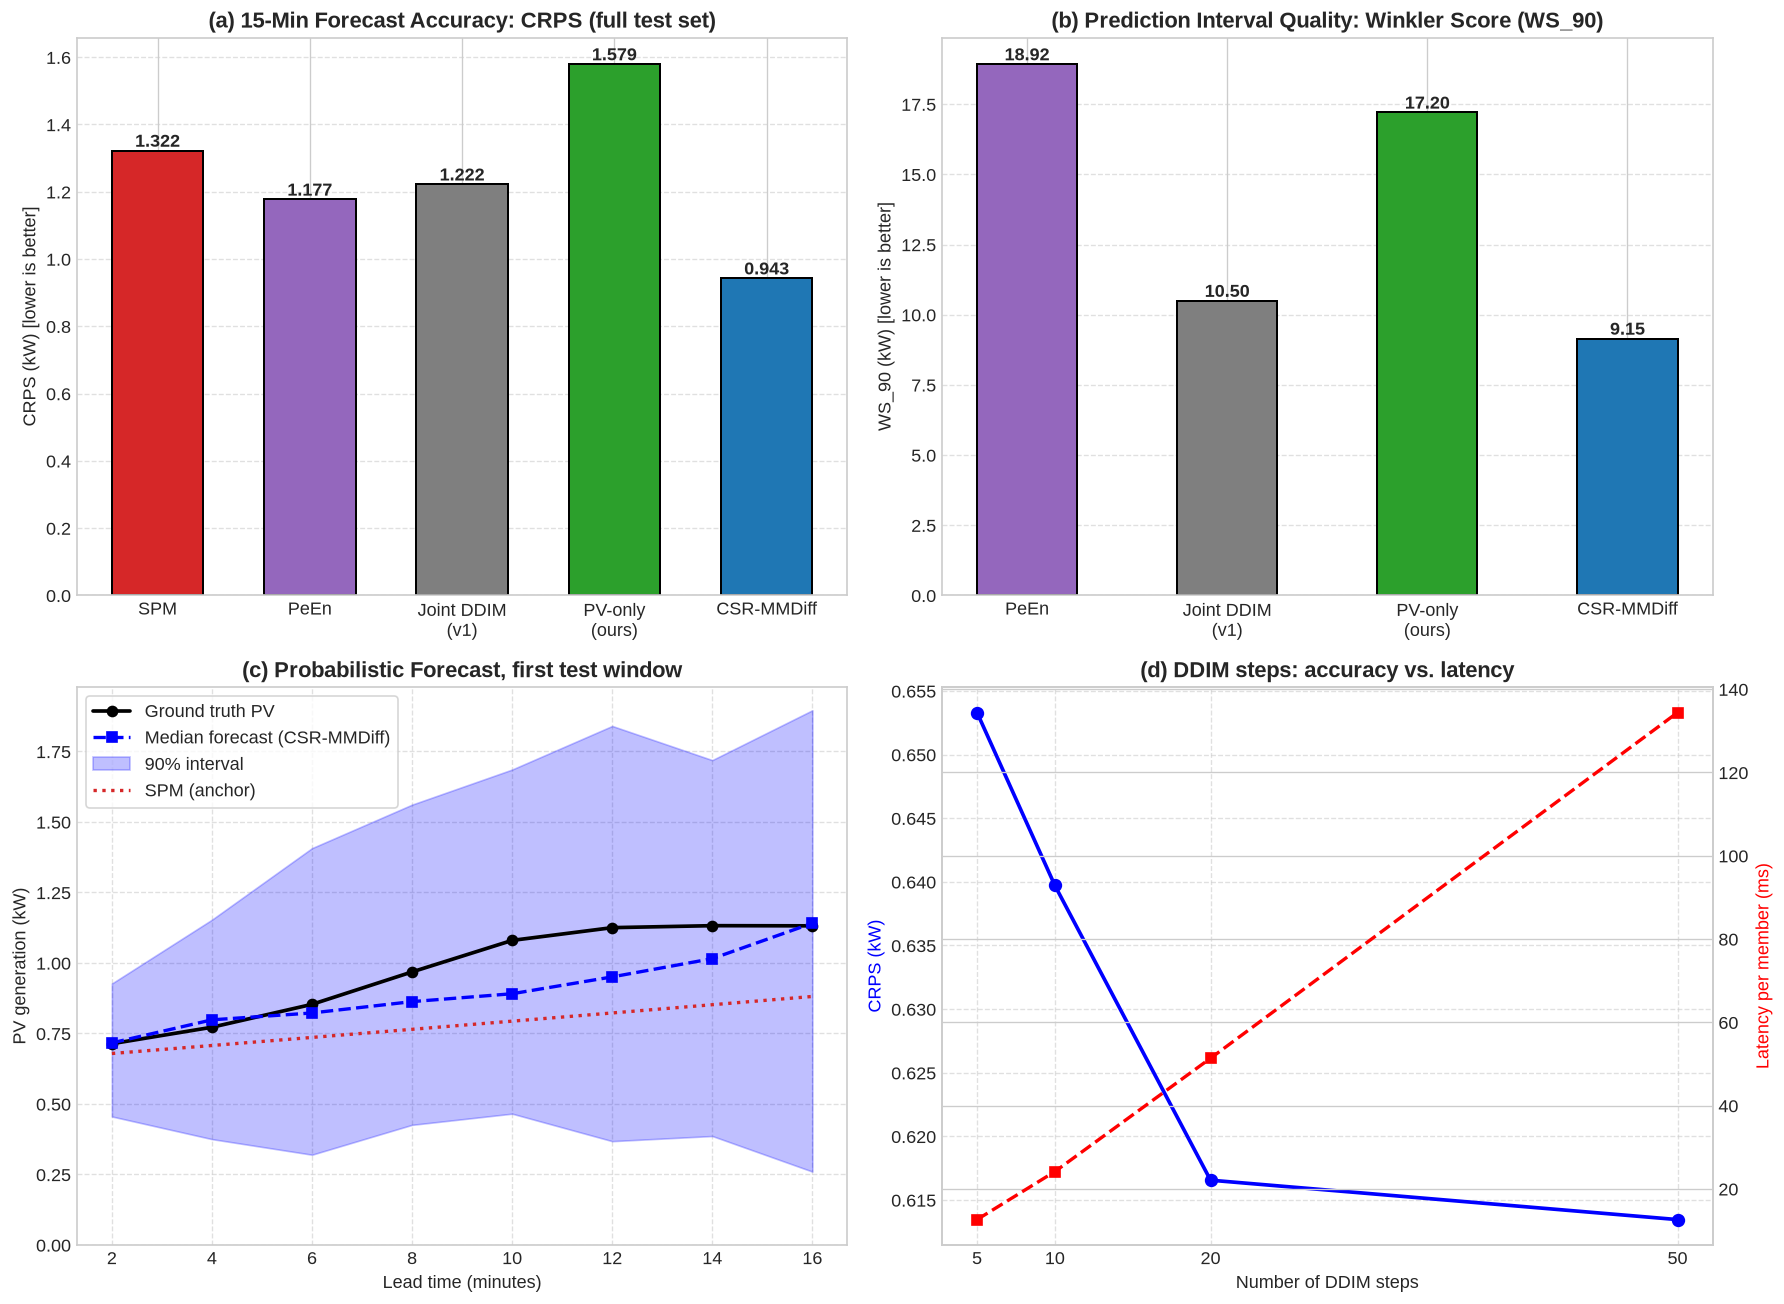

Saved 'ddim_15min_forecasting_results.png'.


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) CRPS comparison
bar_rows = [("SPM", r["spm_crps"], "#d62728"), ("PeEn", r["peen_crps"], "#9467bd")]
if np.isfinite(r["two_stage_crps"]):
    bar_rows.append(("Two-Stage", r["two_stage_crps"], "#ff7f0e"))
if v1 is not None:
    bar_rows.append(("Joint DDIM\n(v1)", v1["crps_kw"], "#7f7f7f"))
if r["pv_only_crps"] is not None:
    bar_rows.append(("PV-only\n(ours)", r["pv_only_crps"], "#2ca02c"))
bar_rows.append((f"{MODEL_NAME}", r["crps_kw"], "#1f77b4"))
names, vals, cols = zip(*bar_rows)
bars = axes[0, 0].bar(names, vals, color=cols, width=0.6, edgecolor="black", linewidth=1.2)
axes[0, 0].set_title("(a) 15-Min Forecast Accuracy: CRPS (full test set)", fontweight="bold")
axes[0, 0].set_ylabel("CRPS (kW) [lower is better]")
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.6)
for bar in bars:
    y = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width() / 2.0, y, f"{y:.3f}", ha="center", va="bottom", fontweight="bold")

# (b) Winkler score — probabilistic models only
ws_rows = [("PeEn", r["peen_ws"], "#9467bd")]
if v1 is not None:
    ws_rows.append(("Joint DDIM\n(v1)", v1["ws_kw"], "#7f7f7f"))
if r["pv_only_ws"] is not None:
    ws_rows.append(("PV-only\n(ours)", r["pv_only_ws"], "#2ca02c"))
ws_rows.append((f"{MODEL_NAME}", r["ws_kw"], "#1f77b4"))
names, vals, cols = zip(*ws_rows)
bars_ws = axes[0, 1].bar(names, vals, color=cols, width=0.5, edgecolor="black", linewidth=1.2)
axes[0, 1].set_title("(b) Prediction Interval Quality: Winkler Score (WS_90)", fontweight="bold")
axes[0, 1].set_ylabel("WS_90 (kW) [lower is better]")
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.6)
for bar in bars_ws:
    y = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2.0, y, f"{y:.2f}", ha="center", va="bottom", fontweight="bold")

# (c) Example probabilistic trajectory (first test window, not cherry-picked)
true_seq = r["pv_true"][0]
ensemble = r["pv_ensemble"][0]
time_steps = np.arange(2, 2 * len(true_seq) + 1, 2)
axes[1, 0].plot(time_steps, true_seq, "k-o", linewidth=2.2, label="Ground truth PV")
axes[1, 0].plot(time_steps, np.median(ensemble, axis=-1), "b--s", linewidth=2, label=f"Median forecast ({MODEL_NAME})")
axes[1, 0].fill_between(time_steps, np.percentile(ensemble, 5, axis=-1), np.percentile(ensemble, 95, axis=-1),
                        color="blue", alpha=0.25, label="90% interval")
axes[1, 0].plot(time_steps, spm_pred_kw[0], ":", color="tab:red", lw=2, label="SPM (anchor)")
axes[1, 0].set_title("(c) Probabilistic Forecast, first test window", fontweight="bold")
axes[1, 0].set_xlabel("Lead time (minutes)")
axes[1, 0].set_ylabel("PV generation (kW)")
axes[1, 0].set_ylim(bottom=0)
axes[1, 0].legend(frameon=True)
axes[1, 0].grid(True, linestyle="--", alpha=0.6)

# (d) CRPS and latency vs DDIM steps
ax = axes[1, 1]
ax.plot(df_steps["steps"], df_steps["crps"], "bo-", linewidth=2.2, markersize=7, label="CRPS (validation)")
ax.set_xlabel("Number of DDIM steps")
ax.set_ylabel("CRPS (kW)", color="b")
ax.set_xticks(list(df_steps["steps"]))
ax2 = ax.twinx()
ax2.plot(df_steps["steps"], df_steps["ms_per_member"], "rs--", linewidth=2, markersize=6, label="Latency")
ax2.set_ylabel("Latency per member (ms)", color="r")
ax.set_title("(d) DDIM steps: accuracy vs. latency", fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("ddim_15min_forecasting_results.png", dpi=300)
plt.show()
print("Saved 'ddim_15min_forecasting_results.png'.")

## Cell 17: Results Showcase — Visual Summary of the 15-Minute Forecasts

Fan charts for three representative (automatically selected, not cherry-picked) windows,
CRPS / skill / coverage by lead time, calibration diagnostics, and generated vs. observed sky images.

/tmp/ipykernel_235482/480123359.py:14: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(np.abs(y_true - y_pred[..., 0])))


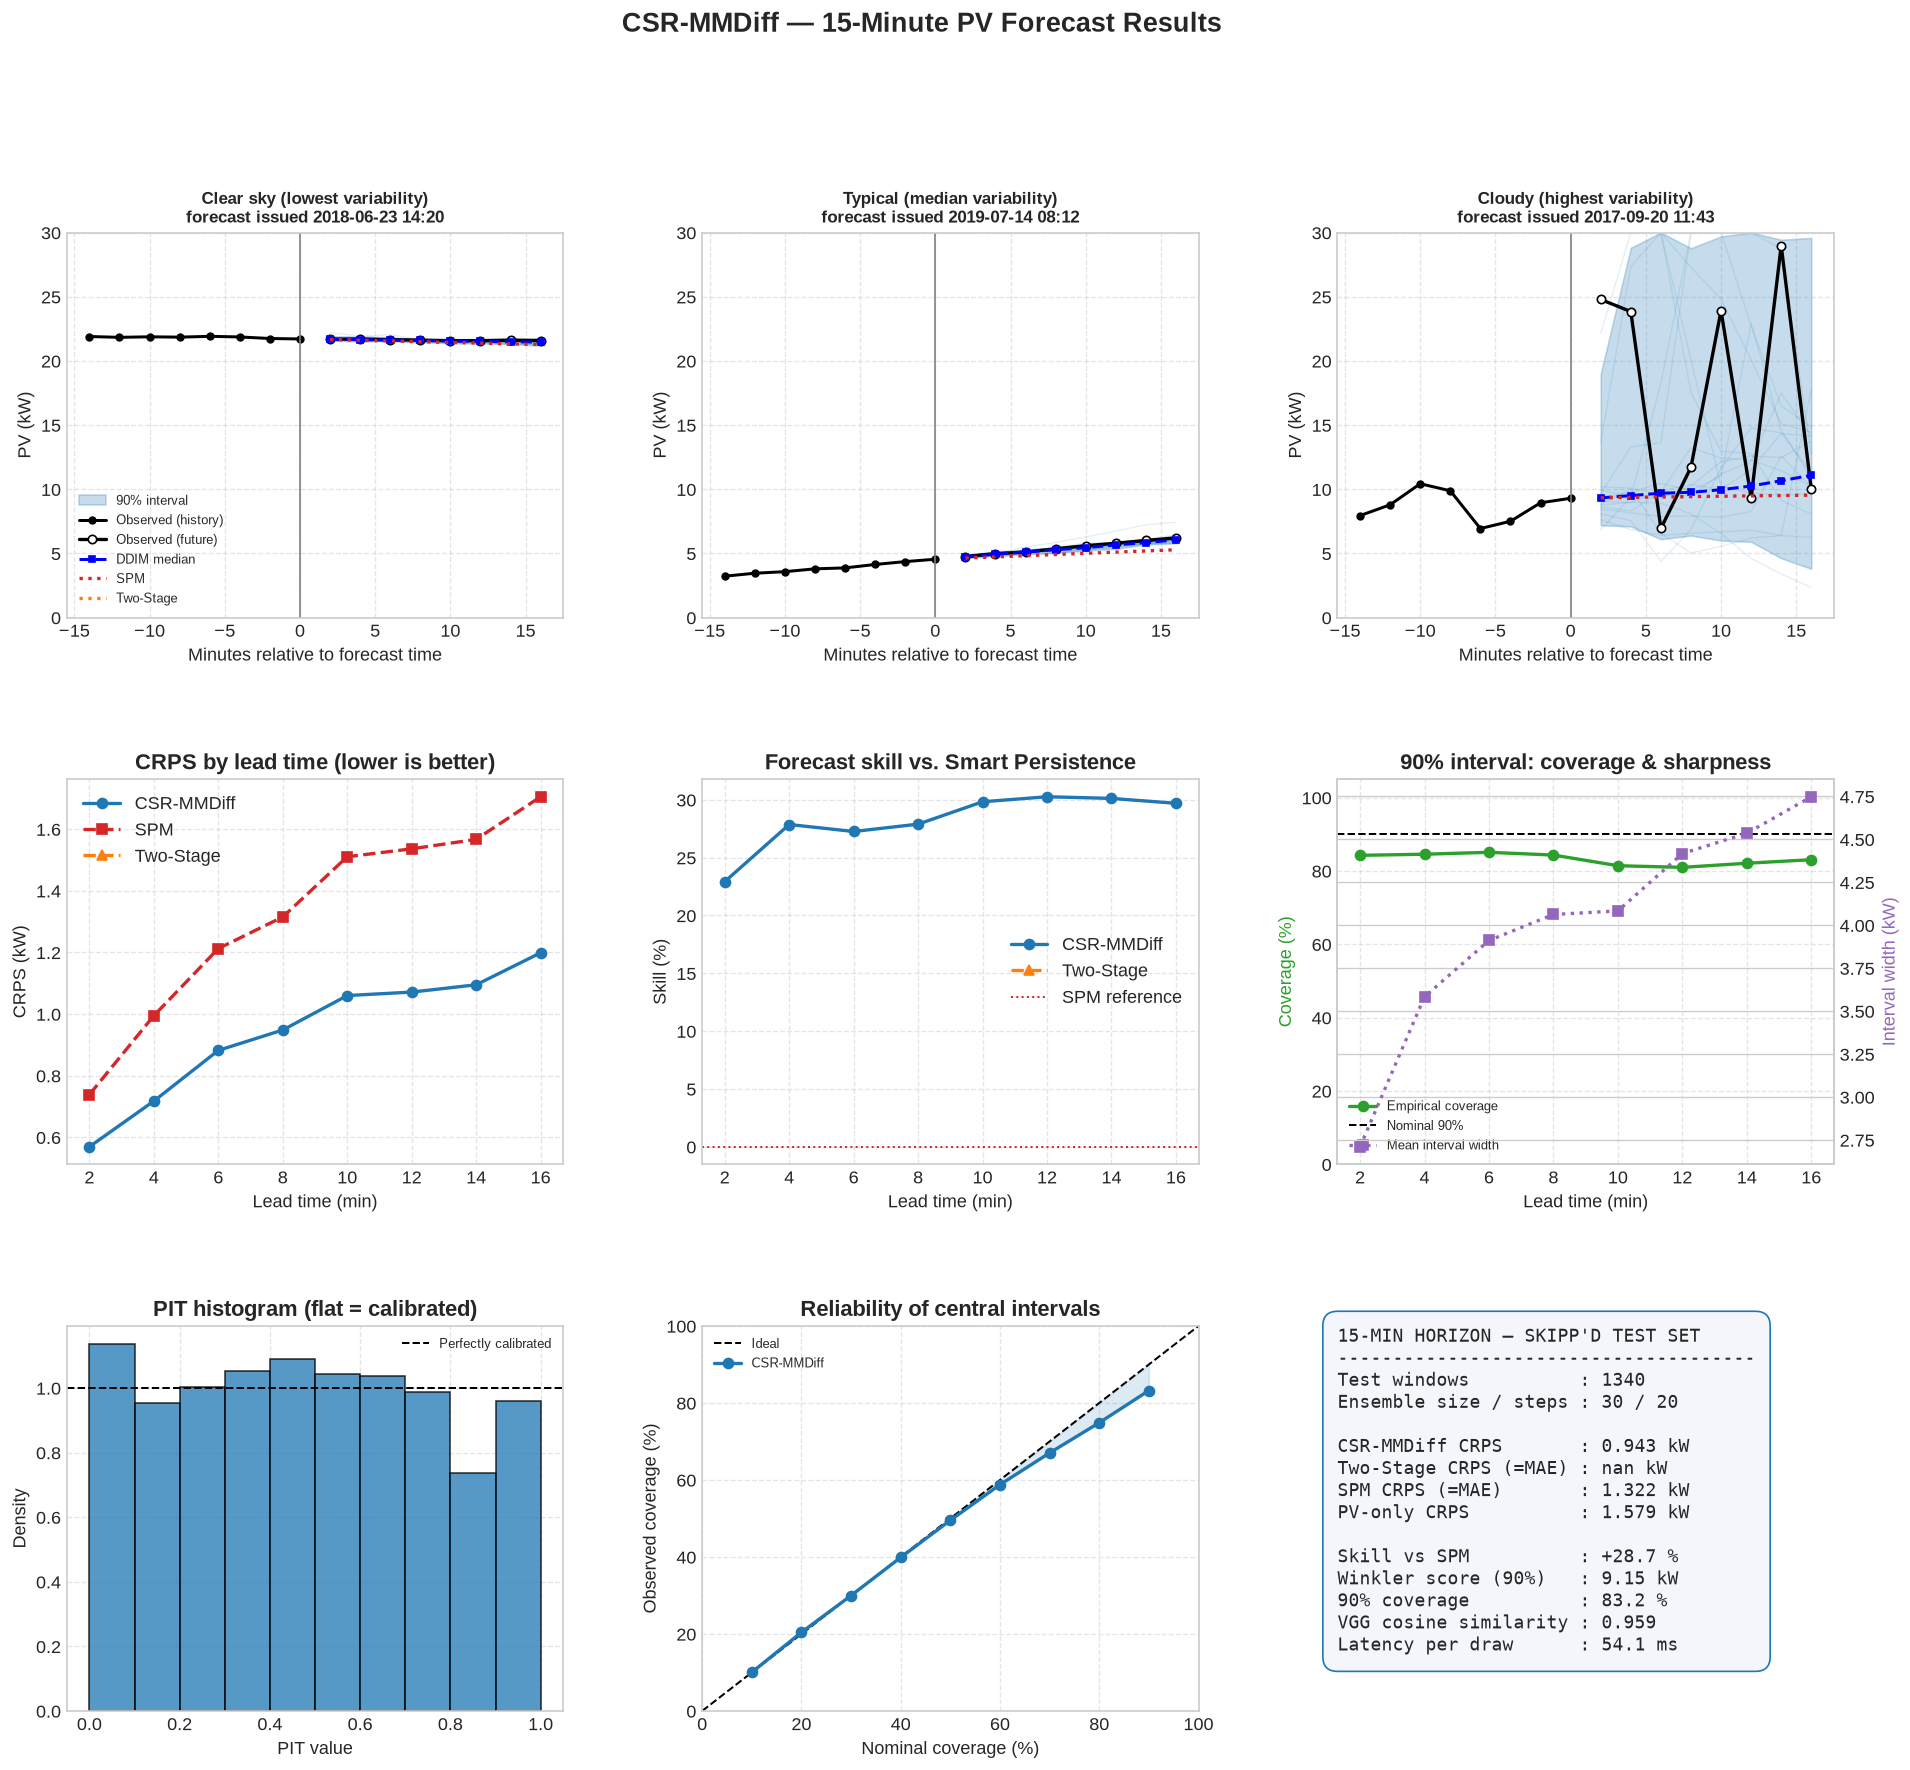

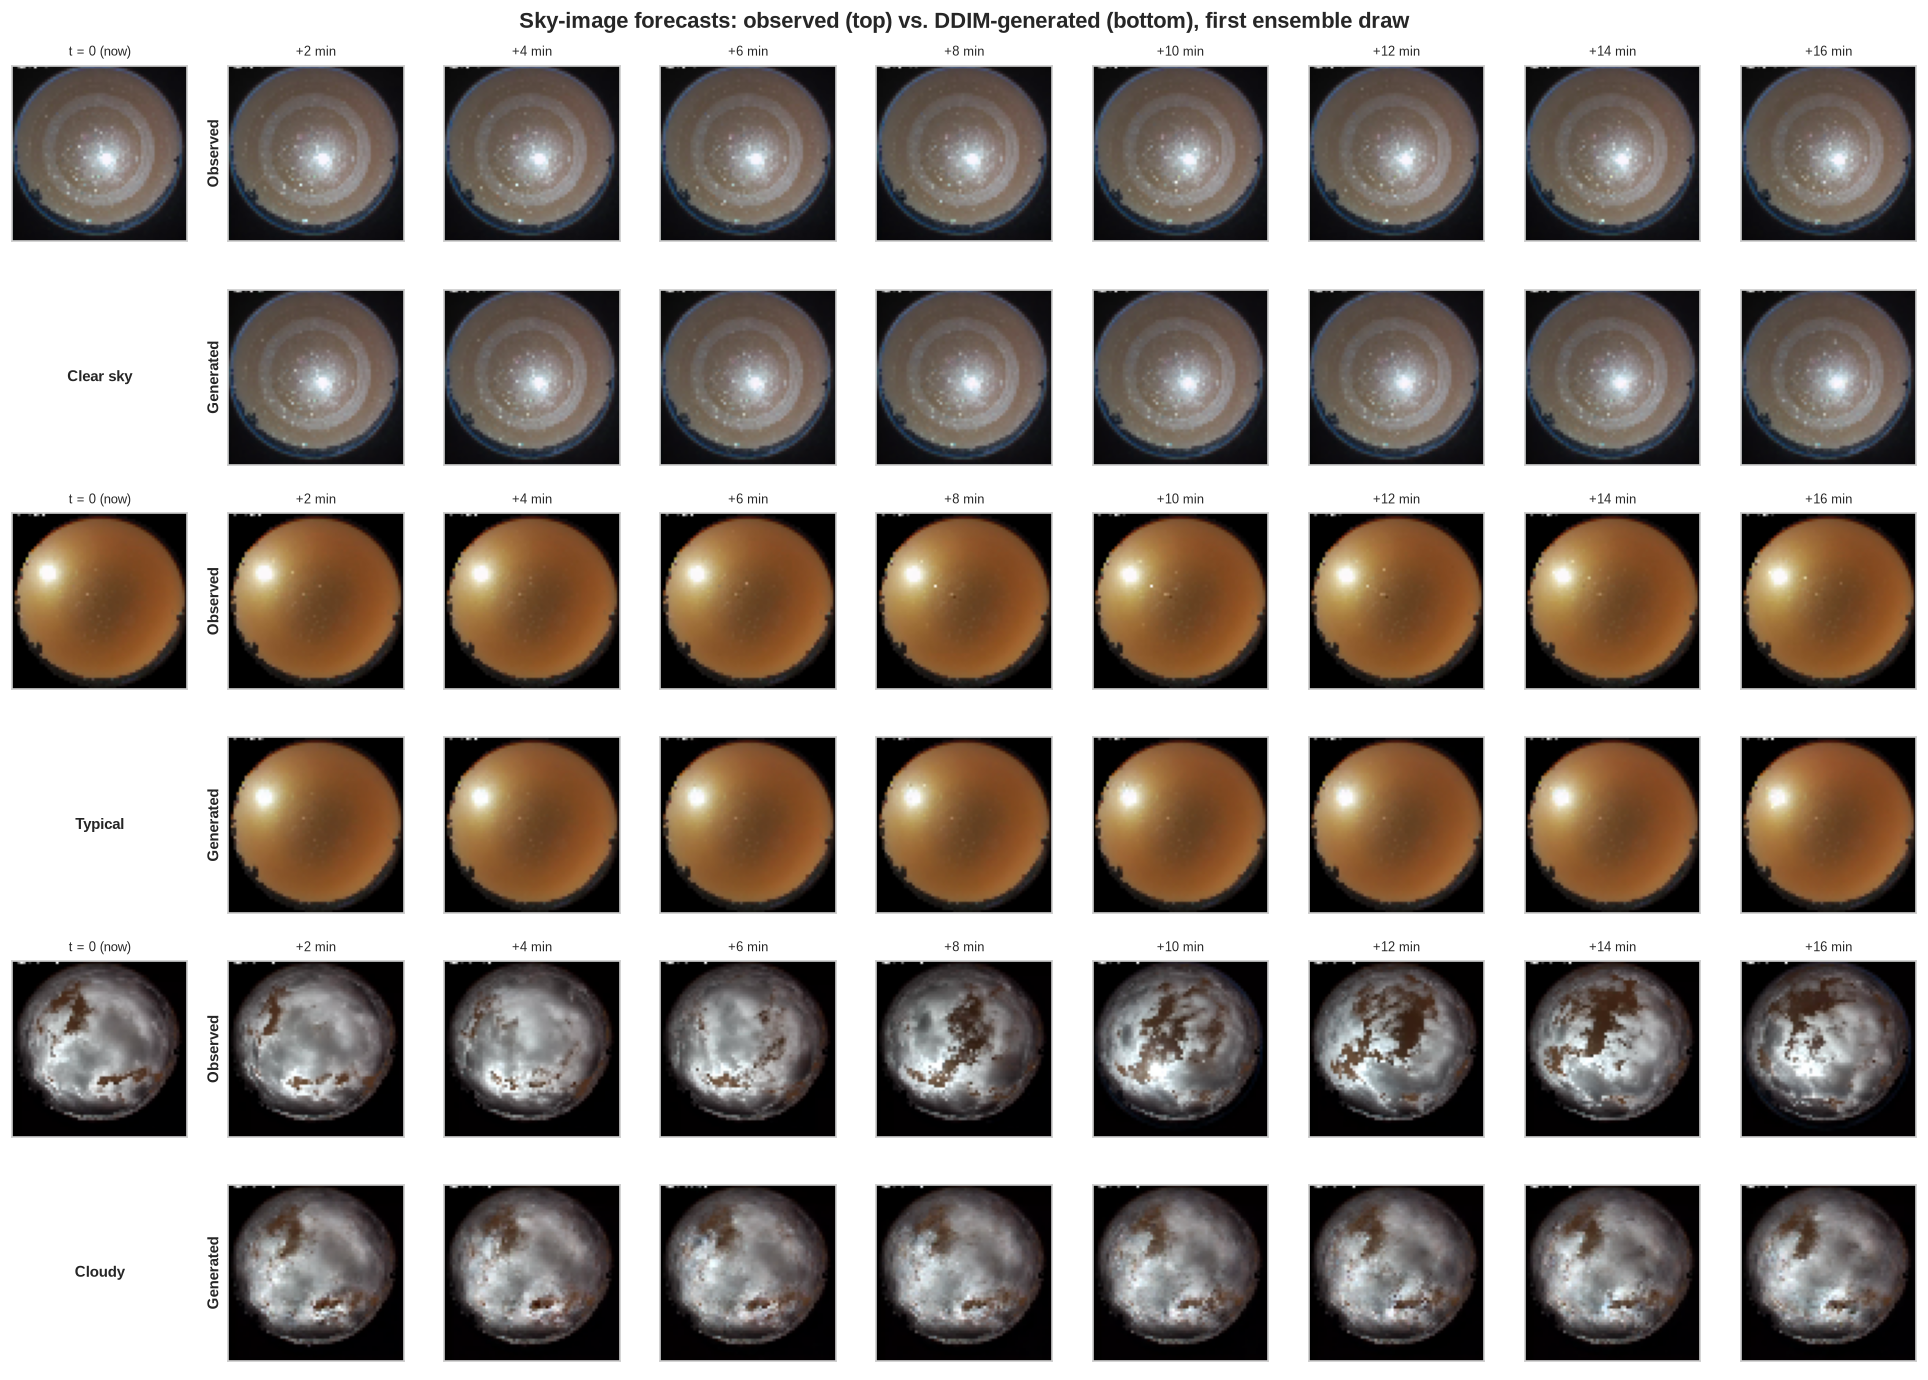

Saved 'showcase_15min_dashboard.png' and 'showcase_15min_sky_images.png'.


In [24]:

import matplotlib.gridspec as gridspec

r = evaluation_results["15min"]
pv_true = np.asarray(r["pv_true"], dtype=np.float64)        # (N, T_f) kW
pv_ens = np.asarray(r["pv_ensemble"], dtype=np.float64)     # (N, T_f, M) kW
N, T_f, M = pv_ens.shape
T_h = cfg.hist_frames
lead_min = np.arange(1, T_f + 1) * cfg.cadence_minutes      # 2, 4, ..., 16 min
hist_min = np.arange(-(T_h - 1), 1) * cfg.cadence_minutes   # -14, ..., 0 min

ens_med = np.median(pv_ens, axis=-1)
ens_p05 = np.percentile(pv_ens, 5, axis=-1)
ens_p95 = np.percentile(pv_ens, 95, axis=-1)
spm_kw = np.asarray(spm_pred_kw, dtype=np.float64).reshape(N, T_f)
two_kw = np.asarray(two_stage_pred_kw, dtype=np.float64).reshape(N, T_f)

# ---- Per-lead-time scores
crps_lead = {
    "CSR-MMDiff": np.array([compute_crps(pv_true[:, k], pv_ens[:, k, :]) for k in range(T_f)]),
    "SPM": np.array([compute_crps(pv_true[:, k], spm_kw[:, k:k + 1]) for k in range(T_f)]),
    "Two-Stage": np.array([compute_crps(pv_true[:, k], two_kw[:, k:k + 1]) for k in range(T_f)]),
}
skill_lead = {
    name: 100.0 * (1.0 - v / np.maximum(crps_lead["SPM"], 1e-6))
    for name, v in crps_lead.items() if name != "SPM"
}
coverage_lead = np.mean((pv_true >= ens_p05) & (pv_true <= ens_p95), axis=0)
width_lead = np.mean(ens_p95 - ens_p05, axis=0)

# ---- Calibration: reliability of central intervals + randomized PIT
nominal = np.arange(10, 100, 10)
empirical = np.array([
    np.mean((pv_true >= np.percentile(pv_ens, 50 - q / 2, axis=-1))
            & (pv_true <= np.percentile(pv_ens, 50 + q / 2, axis=-1)))
    for q in nominal
])
rng_pit = np.random.default_rng(RANDOM_SEED)
below = (pv_ens < pv_true[..., None]).sum(-1)
ties = (pv_ens == pv_true[..., None]).sum(-1)   # night-time zeros create ties -> randomize
pit = (below + rng_pit.uniform(size=below.shape) * (ties + 1)) / (M + 1)

# ---- Automatic selection of 3 daytime windows by variability
variability = np.abs(
    np.diff(np.concatenate([pv_hist_kw[:, -1:], pv_true], axis=1), axis=1)
).mean(axis=1)
daytime = pv_true.mean(axis=1) > 0.15 * PV_RATED_CAPACITY_KW
cand = np.where(daytime)[0] if daytime.sum() >= 3 else np.arange(N)
v = variability[cand]
showcase = {
    "Clear sky (lowest variability)": int(cand[np.argmin(v)]),
    "Typical (median variability)": int(cand[np.argsort(v)[len(v) // 2]]),
    "Cloudy (highest variability)": int(cand[np.argmax(v)]),
}

# =====================================================================
# FIGURE 1: forecast dashboard
# =====================================================================
fig = plt.figure(figsize=(19, 16))
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.28)

# Row 0: fan charts
for j, (label, i) in enumerate(showcase.items()):
    ax = fig.add_subplot(gs[0, j])
    for m in range(min(M, 15)):
        ax.plot(lead_min, pv_ens[i, :, m], color="tab:blue", alpha=0.12, lw=0.8)
    ax.fill_between(lead_min, ens_p05[i], ens_p95[i], color="tab:blue", alpha=0.25, label="90% interval")
    ax.plot(hist_min, pv_hist_kw[i], "k-o", ms=4, lw=1.8, label="Observed (history)")
    ax.plot(lead_min, pv_true[i], "k-o", mfc="white", ms=5, lw=2, label="Observed (future)")
    ax.plot(lead_min, ens_med[i], "b--s", ms=4, lw=1.8, label="DDIM median")
    ax.plot(lead_min, spm_kw[i], ":", color="tab:red", lw=2, label="SPM")
    ax.plot(lead_min, two_kw[i], ":", color="tab:orange", lw=2, label="Two-Stage")
    ax.axvline(0, color="grey", lw=1)
    t_now = pd.to_datetime(hist_times_te[i, -1])
    ax.set_title(f"{label}\nforecast issued {t_now:%Y-%m-%d %H:%M}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Minutes relative to forecast time")
    ax.set_ylabel("PV (kW)")
    ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.grid(True, linestyle="--", alpha=0.5)
    if j == 0:
        ax.legend(fontsize=8, loc="lower left")

# Row 1: CRPS by lead, skill by lead, coverage/width by lead
ax = fig.add_subplot(gs[1, 0])
styles = {"CSR-MMDiff": ("tab:blue", "o-"), "SPM": ("tab:red", "s--"), "Two-Stage": ("tab:orange", "^--")}
for name, vals in crps_lead.items():
    c, st = styles[name]
    ax.plot(lead_min, vals, st, color=c, lw=2, label=name)
ax.set_title("CRPS by lead time (lower is better)", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("CRPS (kW)")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[1, 1])
for name, vals in skill_lead.items():
    c, st = styles[name]
    ax.plot(lead_min, vals, st, color=c, lw=2, label=name)
ax.axhline(0, color="tab:red", lw=1.2, ls=":", label="SPM reference")
ax.set_title("Forecast skill vs. Smart Persistence", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Skill (%)")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[1, 2])
ax.plot(lead_min, coverage_lead * 100, "o-", color="tab:green", lw=2, label="Empirical coverage")
ax.axhline(90, color="k", ls="--", lw=1.2, label="Nominal 90%")
ax.set_ylim(0, 105)
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Coverage (%)", color="tab:green")
ax2 = ax.twinx()
ax2.plot(lead_min, width_lead, "s:", color="tab:purple", lw=2, label="Mean interval width")
ax2.set_ylabel("Interval width (kW)", color="tab:purple")
ax.set_title("90% interval: coverage & sharpness", fontweight="bold")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left"); ax.grid(True, linestyle="--", alpha=0.5)

# Row 2: PIT histogram, reliability diagram, summary panel
ax = fig.add_subplot(gs[2, 0])
ax.hist(pit.ravel(), bins=10, range=(0, 1), density=True, color="tab:blue", edgecolor="black", alpha=0.75)
ax.axhline(1.0, color="k", ls="--", lw=1.2, label="Perfectly calibrated")
ax.set_title("PIT histogram (flat = calibrated)", fontweight="bold")
ax.set_xlabel("PIT value"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[2, 1])
ax.plot([0, 100], [0, 100], "k--", lw=1.2, label="Ideal")
ax.plot(nominal, empirical * 100, "o-", color="tab:blue", lw=2, label="CSR-MMDiff")
ax.fill_between(nominal, nominal, empirical * 100, color="tab:blue", alpha=0.15)
ax.set_title("Reliability of central intervals", fontweight="bold")
ax.set_xlabel("Nominal coverage (%)"); ax.set_ylabel("Observed coverage (%)")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.legend(fontsize=8)
ax.grid(True, linestyle="--", alpha=0.5)

ax = fig.add_subplot(gs[2, 2]); ax.axis("off")
summary = (
    f"15-MIN HORIZON — SKIPP'D TEST SET\n"
    f"{'-' * 38}\n"
    f"Test windows          : {r['n_windows']}\n"
    f"Ensemble size / steps : {r['m_samples']} / {r['ddim_steps']}\n\n"
    f"CSR-MMDiff CRPS       : {r['crps_kw']:.3f} kW\n"
    f"Two-Stage CRPS (=MAE) : {r['two_stage_crps']:.3f} kW\n"
    f"SPM CRPS (=MAE)       : {r['spm_crps']:.3f} kW\n"
    + (f"PV-only CRPS          : {r['pv_only_crps']:.3f} kW\n" if r["pv_only_crps"] is not None else "")
    + f"\nSkill vs SPM          : {r['fs_percent']:+.1f} %\n"
    f"Winkler score (90%)   : {r['ws_kw']:.2f} kW\n"
    f"90% coverage          : {r['coverage_90'] * 100:.1f} %\n"
    f"VGG cosine similarity : {r['vgg_cs']:.3f}\n"
    f"Latency per draw      : {r['latency_ms']:.1f} ms"
)
ax.text(0.0, 1.0, summary, va="top", ha="left", family="monospace", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.8", facecolor="#f4f6fb", edgecolor="#1f77b4"))

fig.suptitle("CSR-MMDiff — 15-Minute PV Forecast Results", fontsize=16, fontweight="bold", y=0.995)
plt.savefig("showcase_15min_dashboard.png", dpi=250, bbox_inches="tight")
plt.show()

# =====================================================================
# FIGURE 2: observed vs generated sky images for the same windows
# =====================================================================
n_cols = T_f + 1
n_rows = 2 * len(showcase)
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(1.8 * n_cols, 1.95 * n_rows))
for j, (label, i) in enumerate(showcase.items()):
    now_img = denormalize_images(img_hist_norm[i, -1])
    true_imgs = denormalize_images(img_true_norm[i])
    gen_imgs = denormalize_images(sample_img_first[i])
    for row, (imgs, name) in enumerate([(true_imgs, "Observed"), (gen_imgs, "Generated")]):
        rr = 2 * j + row
        for c in range(n_cols):
            ax = axes2[rr, c]
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                if row == 0:
                    ax.imshow(now_img)
                    ax.set_title("t = 0 (now)", fontsize=8)
                else:
                    ax.axis("off")
                    ax.text(0.5, 0.5, label.split(" (")[0], ha="center", va="center",
                            fontsize=9, fontweight="bold", transform=ax.transAxes)
            else:
                ax.imshow(imgs[c - 1])
                if rr == 0 or row == 0:
                    ax.set_title(f"+{lead_min[c - 1]} min", fontsize=8)
            if c == 1:
                ax.set_ylabel(name, fontsize=9, fontweight="bold")
fig2.suptitle("Sky-image forecasts: observed (top) vs. DDIM-generated (bottom), first ensemble draw",
              fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("showcase_15min_sky_images.png", dpi=250, bbox_inches="tight")
plt.show()
print("Saved 'showcase_15min_dashboard.png' and 'showcase_15min_sky_images.png'.")

## Cell 18: Forecasted vs. Observed (Original) Values

Point-error metrics, scatter plots against the 1:1 line, error distributions, error by lead time,
sky-image fidelity vs. an image-persistence baseline, and full-day time series against the raw
1-minute measurements. Everything is exported to CSV.

FORECAST vs OBSERVED — POINT-ERROR METRICS (all test windows)
                     MAE (kW)  RMSE (kW)  MBE (kW)  nRMSE (% cap.)     R²  Pearson r
CSR-MMDiff (median)     1.243      2.878     0.208           9.593  0.847      0.923
CSR-MMDiff (mean)       1.253      2.771     0.213           9.237  0.858      0.928
Smart Persistence       1.322      3.087    -0.037          10.290  0.824      0.912
Two-Stage                 NaN        NaN       NaN             NaN    NaN        NaN

Daytime windows only (mean observed PV > 15% of capacity):
                     MAE (kW)  RMSE (kW)  MBE (kW)  nRMSE (% cap.)     R²  Pearson r
CSR-MMDiff (median)     1.391      3.122     0.209          10.405  0.732      0.863
CSR-MMDiff (mean)       1.391      2.991     0.198           9.970  0.754      0.872
Smart Persistence       1.481      3.354    -0.048          11.181  0.690      0.845
Two-Stage                 NaN        NaN       NaN             NaN    NaN        NaN

MAE (kW) by lead time:
    

/home/haseebumer/skippd-solar-forecasting/aienv/lib/python3.11/site-packages/matplotlib/axes/_axes.py:7487: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/home/haseebumer/skippd-solar-forecasting/aienv/lib/python3.11/site-packages/matplotlib/axes/_axes.py:7488: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))
/home/haseebumer/skippd-solar-forecasting/aienv/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


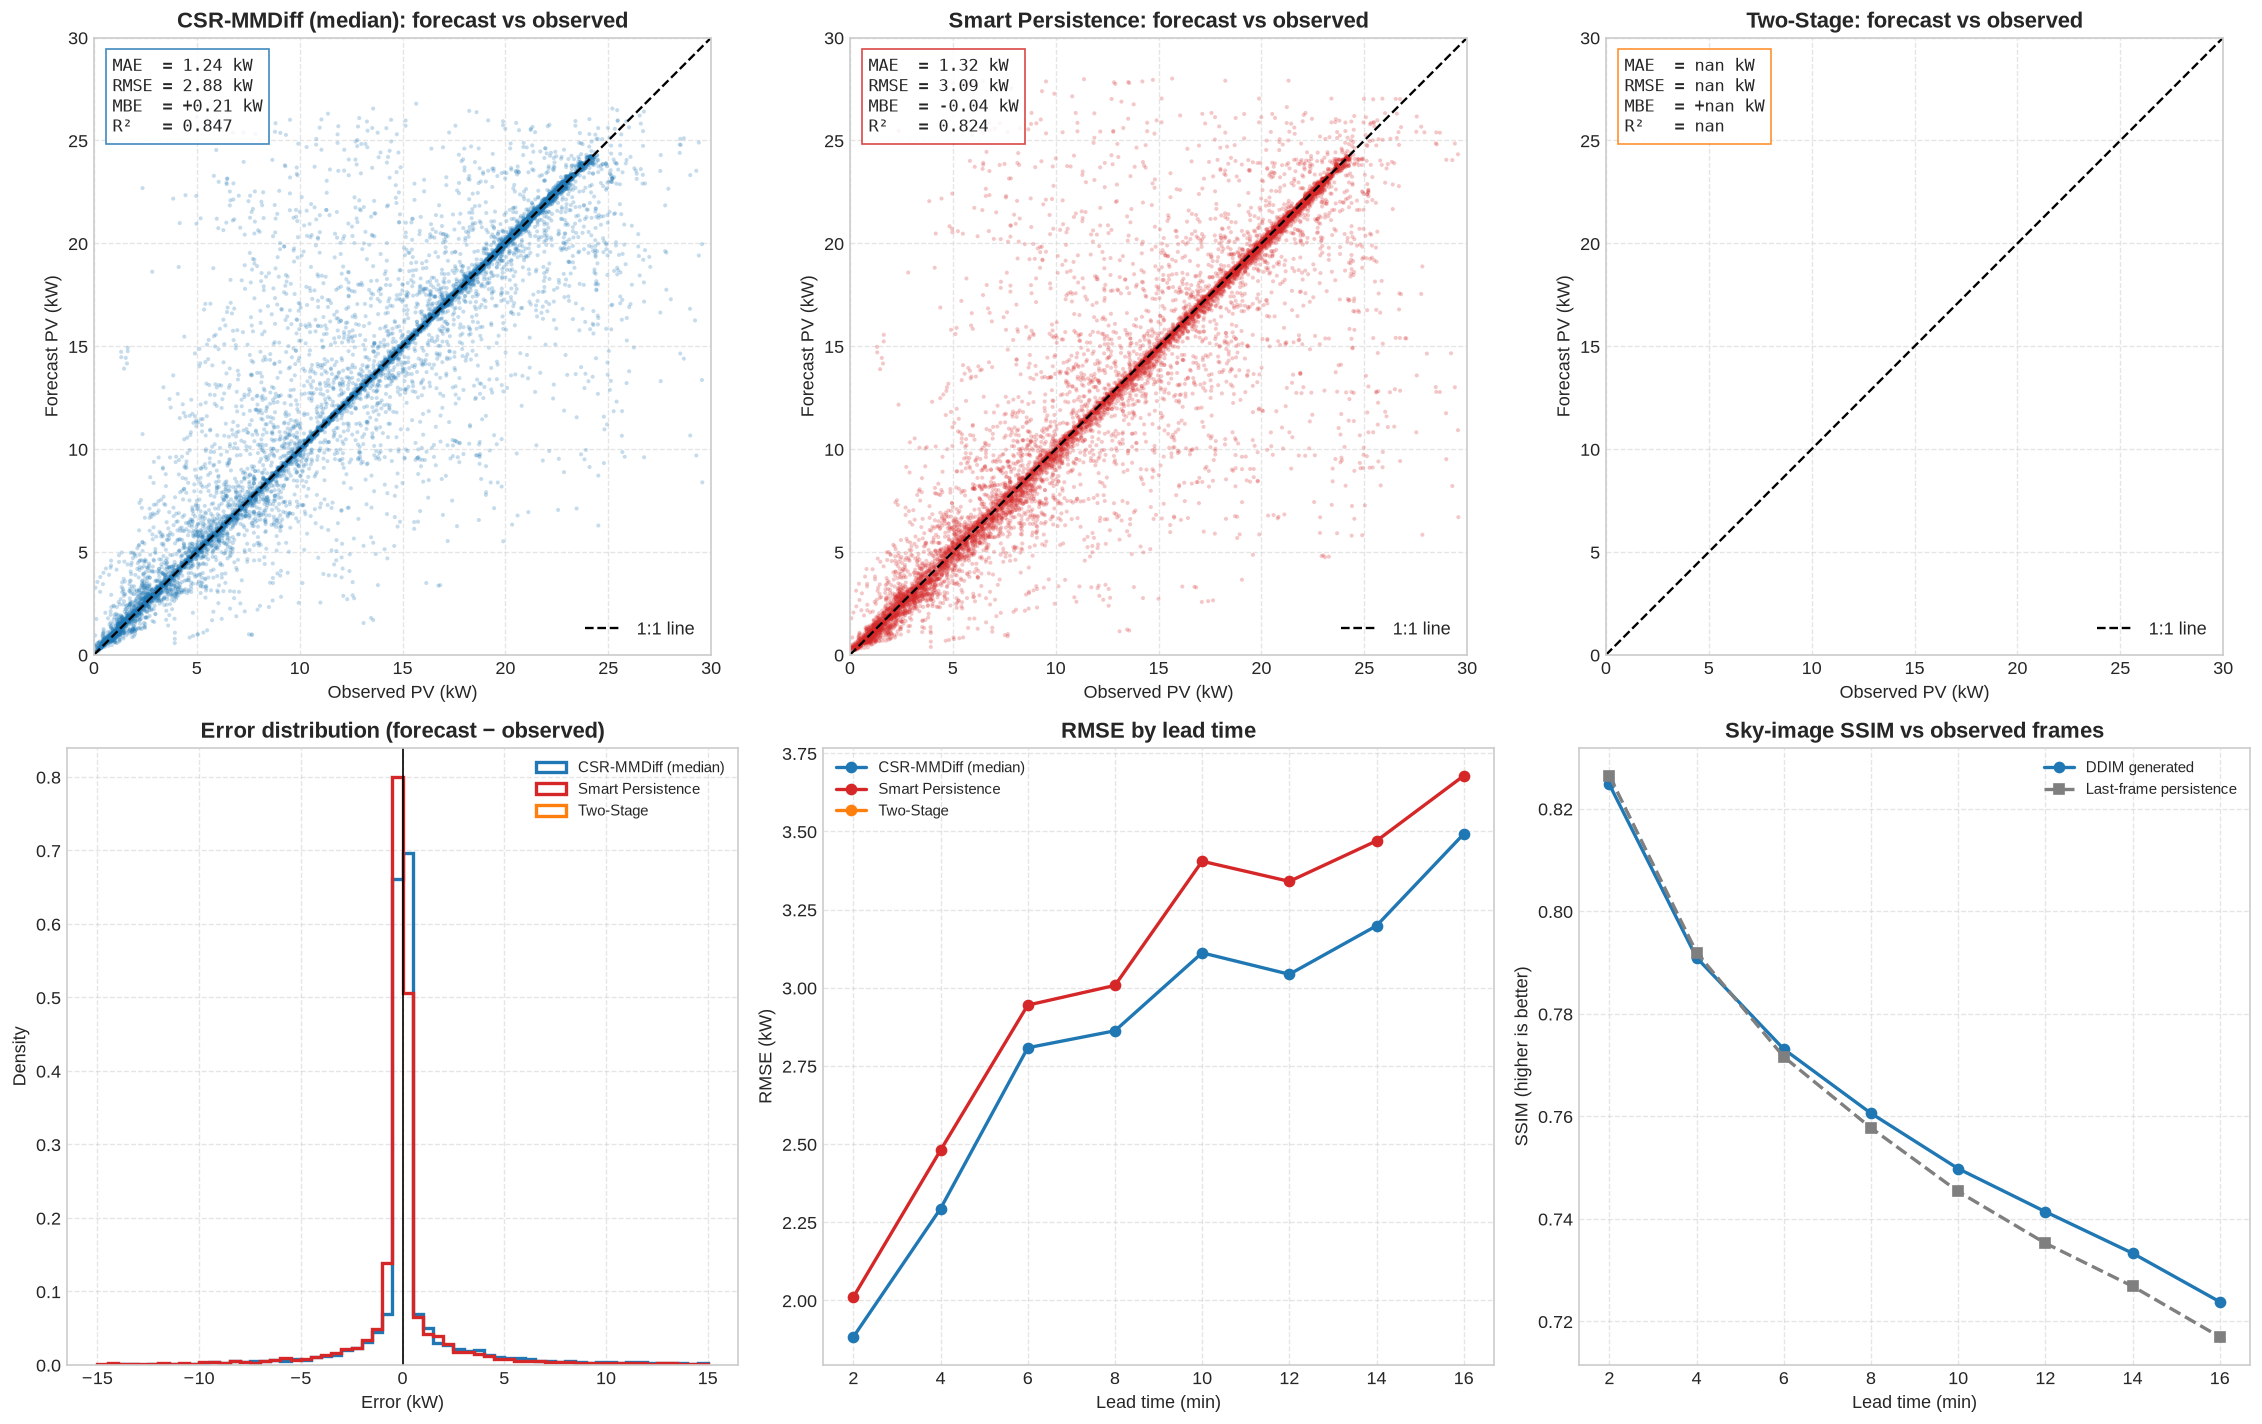

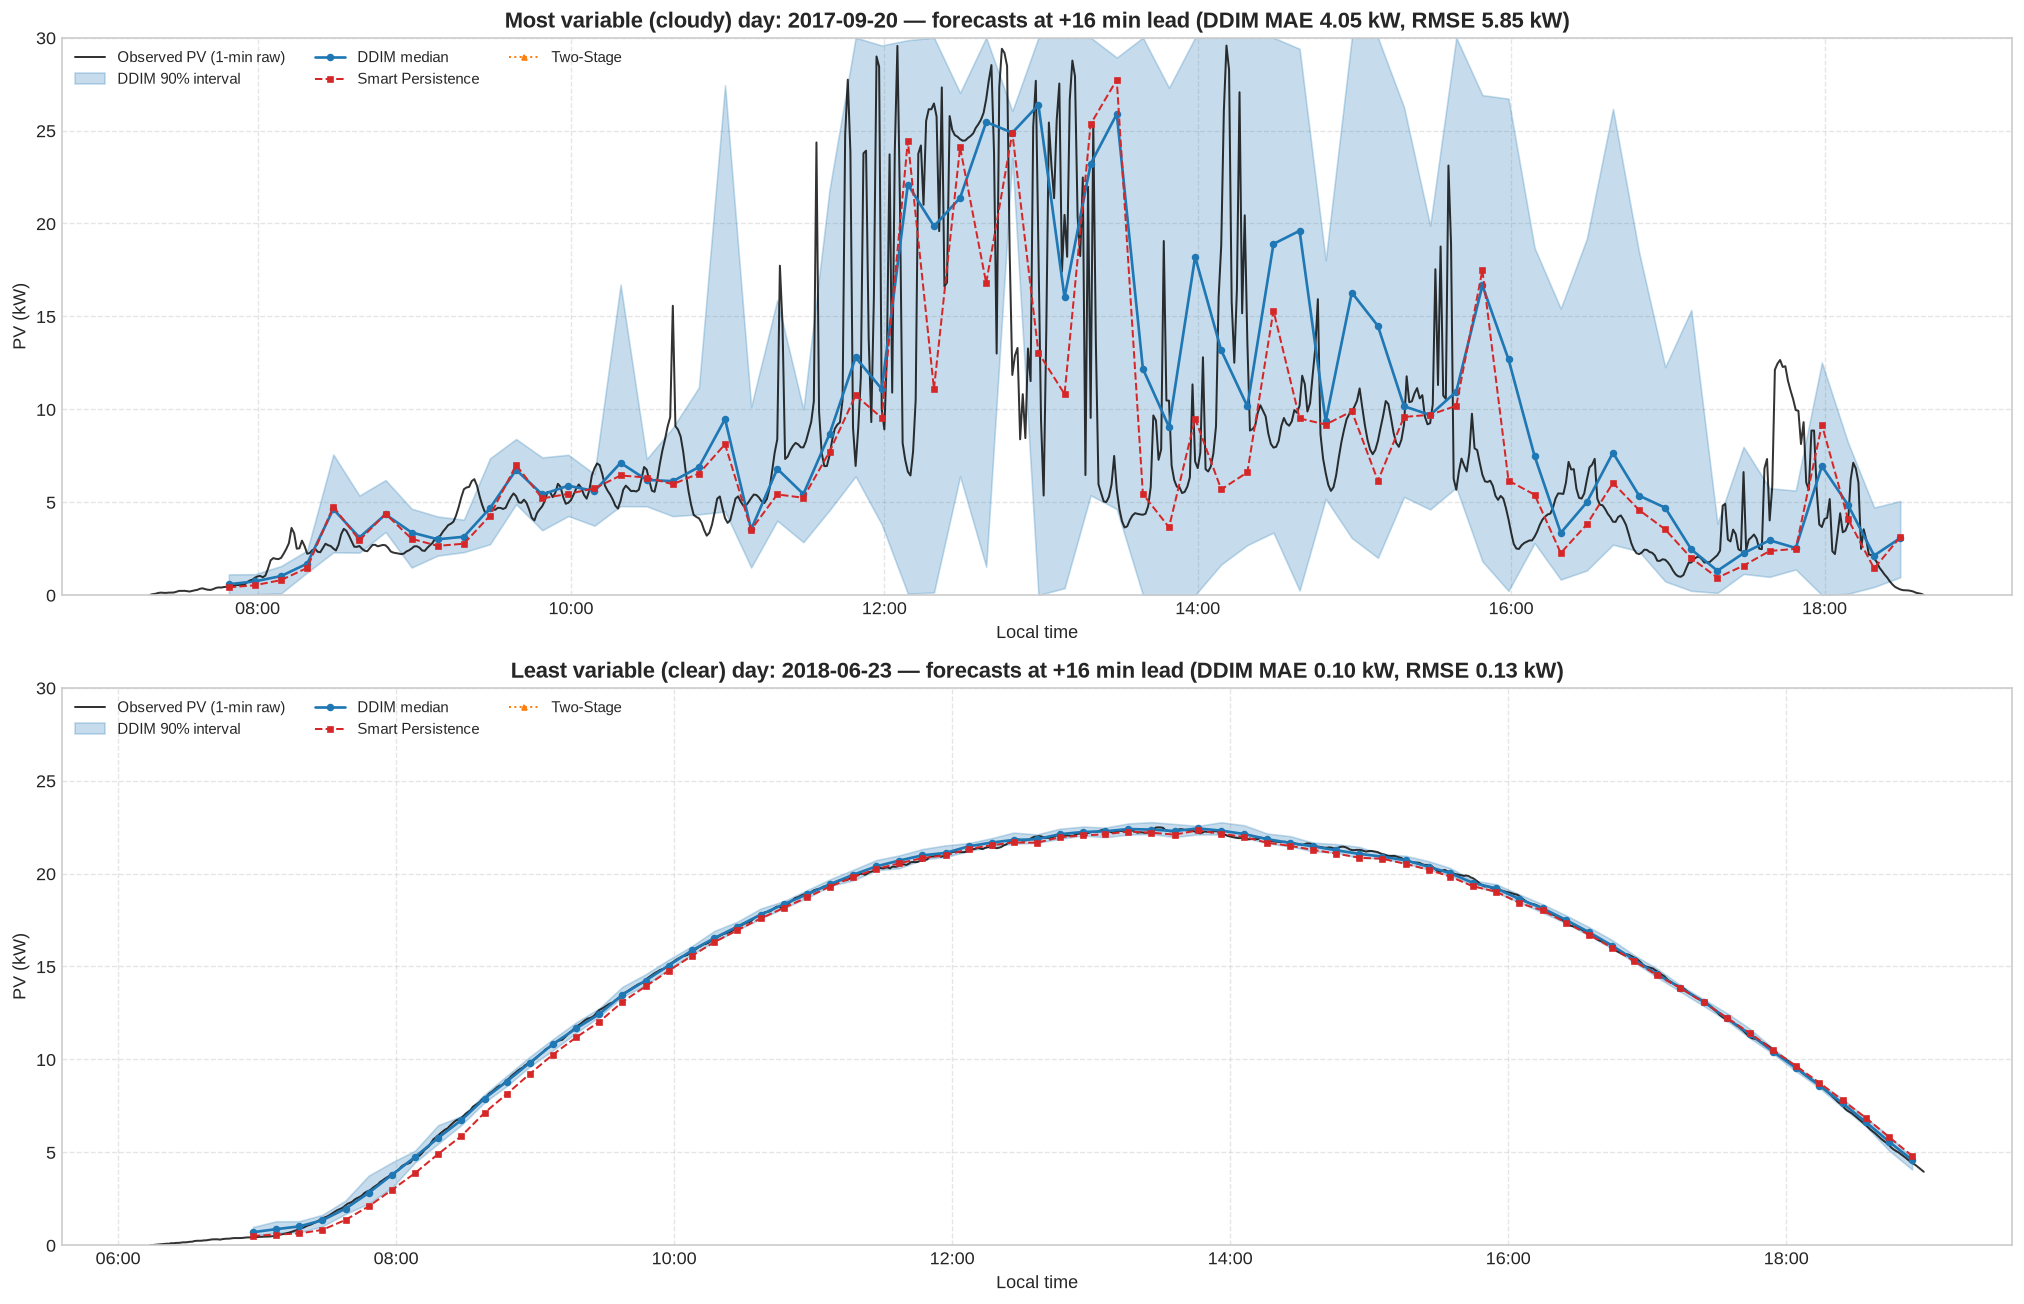


Saved figures: comparison_15min_forecast_vs_observed.png, comparison_15min_daily_timeseries.png
Saved tables : forecast_vs_observed_15min.csv, point_metrics_15min.csv, mae_by_lead_15min.csv


In [25]:
def det_scores(y, yhat):
    y, yhat = np.ravel(y), np.ravel(yhat)
    err = yhat - y
    sst = np.sum((y - y.mean()) ** 2)
    return {
        "MAE (kW)": np.mean(np.abs(err)),
        "RMSE (kW)": np.sqrt(np.mean(err ** 2)),
        "MBE (kW)": np.mean(err),
        "nRMSE (% cap.)": 100 * np.sqrt(np.mean(err ** 2)) / PV_RATED_CAPACITY_KW,
        "R²": 1 - np.sum(err ** 2) / max(sst, 1e-12),
        "Pearson r": np.corrcoef(y, yhat)[0, 1] if np.std(yhat) > 0 else np.nan,
    }


forecasts = {
    "CSR-MMDiff (median)": ens_med,
    "CSR-MMDiff (mean)": pv_ens.mean(axis=-1),
    "Smart Persistence": spm_kw,
    "Two-Stage": two_kw,
}

# ---- 1. Overall and daytime-only error tables
print("=" * 90)
print("FORECAST vs OBSERVED — POINT-ERROR METRICS (all test windows)")
print("=" * 90)
df_all = pd.DataFrame({k: det_scores(pv_true, v) for k, v in forecasts.items()}).T
print(df_all.round(3).to_string())

print("\nDaytime windows only (mean observed PV > 15% of capacity):")
df_day = pd.DataFrame({k: det_scores(pv_true[daytime], v[daytime]) for k, v in forecasts.items()}).T
print(df_day.round(3).to_string())

# ---- 2. MAE by lead time
df_lead = pd.DataFrame(
    {k: np.mean(np.abs(v - pv_true), axis=0) for k, v in forecasts.items()},
    index=[f"+{m} min" for m in lead_min],
)
print("\nMAE (kW) by lead time:")
print(df_lead.round(3).to_string())

# ---- 3. Sky-image fidelity per lead: generated vs observed, and 'last frame persists' baseline
with tf.device("/CPU:0"):
    ssim_gen, ssim_pers, mae_gen, mae_pers = [], [], [], []
    last_frame = tf.constant(img_hist_norm[:, -1], tf.float32)
    for k in range(T_f):
        true_k = tf.constant(img_true_norm[:, k], tf.float32)
        gen_k = tf.constant(sample_img_first[:, k], tf.float32)
        ssim_gen.append(float(tf.reduce_mean(tf.image.ssim(gen_k, true_k, max_val=2.0))))
        ssim_pers.append(float(tf.reduce_mean(tf.image.ssim(last_frame, true_k, max_val=2.0))))
        mae_gen.append(float(tf.reduce_mean(tf.abs(gen_k - true_k))) * 127.5)
        mae_pers.append(float(tf.reduce_mean(tf.abs(last_frame - true_k))) * 127.5)
print("\nSky-image comparison (mean over test windows):")
print(pd.DataFrame(
    {"SSIM generated": ssim_gen, "SSIM persistence": ssim_pers,
     "Pixel MAE generated": mae_gen, "Pixel MAE persistence": mae_pers},
    index=[f"+{m} min" for m in lead_min],
).round(3).to_string())

# =====================================================================
# FIGURE 3: forecast vs observed diagnostics
# =====================================================================
fig, axes = plt.subplots(2, 3, figsize=(19, 12))
scatter_models = [("CSR-MMDiff (median)", "tab:blue"), ("Smart Persistence", "tab:red"), ("Two-Stage", "tab:orange")]

for ax, (name, color) in zip(axes[0], scatter_models):
    pred = forecasts[name]
    ax.scatter(pv_true.ravel(), pred.ravel(), s=6, alpha=0.25, color=color, edgecolors="none")
    ax.plot([0, PV_RATED_CAPACITY_KW], [0, PV_RATED_CAPACITY_KW], "k--", lw=1.4, label="1:1 line")
    s = det_scores(pv_true, pred)
    ax.text(0.03, 0.97, f"MAE  = {s['MAE (kW)']:.2f} kW\nRMSE = {s['RMSE (kW)']:.2f} kW\n"
                        f"MBE  = {s['MBE (kW)']:+.2f} kW\nR²   = {s['R²']:.3f}",
            transform=ax.transAxes, va="top", family="monospace", fontsize=10,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor=color))
    ax.set_xlim(0, PV_RATED_CAPACITY_KW); ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.set_aspect("equal")
    ax.set_title(f"{name}: forecast vs observed", fontweight="bold")
    ax.set_xlabel("Observed PV (kW)"); ax.set_ylabel("Forecast PV (kW)")
    ax.legend(loc="lower right"); ax.grid(True, linestyle="--", alpha=0.5)

# Error distributions
ax = axes[1, 0]
bins = np.linspace(-15, 15, 61)
for name, color in scatter_models:
    ax.hist((forecasts[name] - pv_true).ravel(), bins=bins, histtype="step", lw=2, color=color,
            density=True, label=name)
ax.axvline(0, color="k", lw=1)
ax.set_title("Error distribution (forecast − observed)", fontweight="bold")
ax.set_xlabel("Error (kW)"); ax.set_ylabel("Density"); ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# RMSE by lead time
ax = axes[1, 1]
for name, color in scatter_models:
    rmse_k = np.sqrt(np.mean((forecasts[name] - pv_true) ** 2, axis=0))
    ax.plot(lead_min, rmse_k, "o-", color=color, lw=2, label=name)
ax.set_title("RMSE by lead time", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("RMSE (kW)"); ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

# Image fidelity by lead time
ax = axes[1, 2]
ax.plot(lead_min, ssim_gen, "o-", color="tab:blue", lw=2, label="DDIM generated")
ax.plot(lead_min, ssim_pers, "s--", color="tab:gray", lw=2, label="Last-frame persistence")
ax.set_title("Sky-image SSIM vs observed frames", fontweight="bold")
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("SSIM (higher is better)")
ax.legend(fontsize=9); ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("comparison_15min_forecast_vs_observed.png", dpi=250, bbox_inches="tight")
plt.show()

# =====================================================================
# FIGURE 4: full-day time series against the raw 1-minute measurements
# =====================================================================
valid_times = pd.to_datetime(np.asarray(r["times_fut"]).ravel()).values.reshape(N, T_f)
test_times_dt = pd.to_datetime(times_test_raw)
test_dates = np.asarray(test_times_dt.date)

uniq_days, counts = np.unique(dates_te, return_counts=True)
eligible = counts >= max(10, counts.max() // 3)
day_var = np.array([variability[dates_te == d].mean() for d in uniq_days])
elig_idx = np.where(eligible)[0] if eligible.any() else np.arange(len(uniq_days))
days_to_plot = {
    "Most variable (cloudy) day": uniq_days[elig_idx[np.argmax(day_var[elig_idx])]],
    "Least variable (clear) day": uniq_days[elig_idx[np.argmin(day_var[elig_idx])]],
}

k_show = T_f - 1  # longest lead (~15-16 min ahead)
fig, axes = plt.subplots(len(days_to_plot), 1, figsize=(17, 5.5 * len(days_to_plot)))
axes = np.atleast_1d(axes)
for ax, (label, d) in zip(axes, days_to_plot.items()):
    raw_mask = test_dates == d
    ax.plot(test_times_dt[raw_mask], test_pv_raw[raw_mask], color="black", lw=1.2, alpha=0.8,
            label="Observed PV (1-min raw)")

    idx = np.where(dates_te == d)[0]
    idx = idx[np.argsort(valid_times[idx, k_show])]
    t = valid_times[idx, k_show]
    ax.fill_between(t, ens_p05[idx, k_show], ens_p95[idx, k_show], color="tab:blue", alpha=0.25,
                    label="DDIM 90% interval")
    ax.plot(t, ens_med[idx, k_show], "o-", color="tab:blue", ms=3.5, lw=1.6, label="DDIM median")
    ax.plot(t, spm_kw[idx, k_show], "s--", color="tab:red", ms=3, lw=1.2, label="Smart Persistence")
    ax.plot(t, two_kw[idx, k_show], "^:", color="tab:orange", ms=3, lw=1.2, label="Two-Stage")

    s_day = det_scores(pv_true[idx, k_show], ens_med[idx, k_show])
    ax.set_title(f"{label}: {d} — forecasts at +{lead_min[k_show]} min lead "
                 f"(DDIM MAE {s_day['MAE (kW)']:.2f} kW, RMSE {s_day['RMSE (kW)']:.2f} kW)",
                 fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel("Local time"); ax.set_ylabel("PV (kW)")
    ax.set_ylim(0, PV_RATED_CAPACITY_KW)
    ax.legend(loc="upper left", fontsize=9, ncol=3); ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("comparison_15min_daily_timeseries.png", dpi=250, bbox_inches="tight")
plt.show()

# ---- Export per-window, per-lead comparison
df_export = pd.DataFrame({
    "window_id": np.repeat(np.arange(N), T_f),
    "valid_time": valid_times.ravel(),
    "lead_min": np.tile(lead_min, N),
    "observed_kw": pv_true.ravel(),
    "ddim_median_kw": ens_med.ravel(),
    "ddim_mean_kw": pv_ens.mean(axis=-1).ravel(),
    "ddim_p05_kw": ens_p05.ravel(),
    "ddim_p95_kw": ens_p95.ravel(),
    "spm_kw": spm_kw.ravel(),
    "two_stage_kw": two_kw.ravel(),
})
df_export["ddim_error_kw"] = df_export["ddim_median_kw"] - df_export["observed_kw"]
df_export["inside_90pct"] = (df_export["observed_kw"] >= df_export["ddim_p05_kw"]) & \
                            (df_export["observed_kw"] <= df_export["ddim_p95_kw"])
df_export.to_csv("forecast_vs_observed_15min.csv", index=False)
df_all.to_csv("point_metrics_15min.csv")
df_lead.to_csv("mae_by_lead_15min.csv")
print("\nSaved figures: comparison_15min_forecast_vs_observed.png, comparison_15min_daily_timeseries.png")
print("Saved tables : forecast_vs_observed_15min.csv, point_metrics_15min.csv, mae_by_lead_15min.csv")